# **Proyecto Integrador: Diabetes en México**

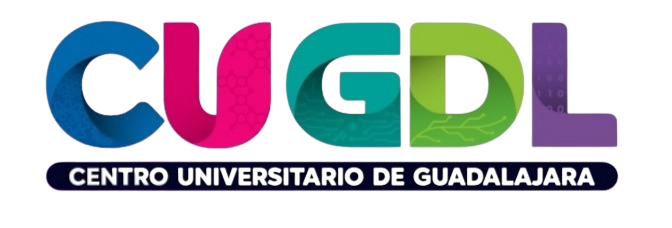

**Integrantes:**

Manuel Dario Ledezma Medina

Natalia Karina Maravilla Godinez

Renata Ramos Alonso

In [ ]:
##Importacion de librerias

In [101]:
import numpy as np # Operaciones matematicas necesarias
import pandas as pd  # Visualizacion de datos
import matplotlib.pyplot as plt # Visualizacion de graficas
import seaborn as sns # Graficas
import time
import funciones as fn

##Descripcion del dataset
**Columnas**

**folio_i**: Identificador único del hogar

**folio_int**: Identificador único del individuo

**sexo**: Sexo del individuo (1 = masculino, 2 = femenino)

**edad**: Edad en años

**Ciudad**: Ciudad de residencia

**Peso**: Peso corporal en kg

**Estatura**: Estatura en cm

**imc:** Índice de masa corporal

**muestra_suero:** Indica si se tomó muestra de suero (1 = sí, 0 = no)

**ac_urico:** Nivel de ácido úrico en sangre

**albu:** Concentración de albúmina en sangre

**col_hdl:** Nivel de colesterol HDL

**col_ldl:** Nivel de colesterol LDL

**colest:** Nivel de colesterol total

**creat:** Nivel de creatinina

**glu_suero:** Concentración de glucosa en suero

**insulina:** Nivel de insulina en sangre

**trig:** Nivel de triglicéridos

**hb1ac:** Hemoglobina glucosilada (HbA1c)

**ponde_venosa:** Ponderador de muestra venosa

**estrato:** Estrato muestral

**est_sel:** Unidad primaria de muestreo

**ponde_hemo:** Ponderador de muestra de hemoglobina

**riesgo_diabetes_cat:** Categoría de riesgo de diabetes (0 = bajo, 1 = moderado, 2 = alto)

## **Descripción de los datos**

In [2]:
url = "https://raw.githubusercontent.com/nataliamaravilla/Diabetes-Mexico-2026B/refs/heads/main/Diabetes_Mexico.csv"
df = pd.read_csv(url)
df.head()

,folio_i,folio_int,sexo,edad,Ciudad,Peso,Estatura,imc,muestra_suero,ac_urico,...,creat,glu_suero,insulina,trig,hb1ac,ponde_venosa,estrato,est_sel,ponde_hemo,riesgo_diabetes_cat
0,2024_01001010,2024_01001010_01,Mujer,89.0,AGUASCALIENTES,NaN,NaN,NaN,1.0,"4,1",...,"0,62",166.0,"4,7",107.0,NaN,"2245,917738",3.0,13.0,"2888,530238",2
1,2024_01001012,2024_01001012_01,Mujer,71.0,AGUASCALIENTES,NaN,NaN,32.0,1.0,"4,3",...,"0,64",98.0,"9,6",132.0,NaN,"2245,917738",3.0,13.0,"2888,530238",1
2,2024_01001016,2024_01001016_02,Mujer,57.0,AGUASCALIENTES,"80,25","170,6",NaN,1.0,"4,9",...,"0,6",128.0,"4,7",263.0,6.0,"4047,445276",3.0,13.0,NaN,2
3,2024_01001016,2024_01001016_05,Mujer,20.0,AGUASCALIENTES,"68,6","166,2",NaN,1.0,"4,9",...,"0,63",112.0,"10,1",238.0,NaN,"13079,14232",3.0,13.0,"13776,80526",2
4,2024_01001031,2024_01001031_01,Hombre,74.0,AGUASCALIENTES,NaN,NaN,NaN,1.0,"6,4",...,"1,09",97.0,"10,2",135.0,NaN,"5292,158204",3.0,13.0,"5824,779445",0


In [3]:
df.shape  # El tamaño del dataset (2549 filas y 24 columnas)

(2549, 24)

In [4]:
df.info()  # Explorando el dataset, en las columnas se ven distintos tipos de datos en las variables, pero hay columnas que se clasifican como categoricas aunque
           # sean numericas, porque estan separados los decimales por comas

<class 'pandas.DataFrame'>
RangeIndex: 2549 entries, 0 to 2548
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   folio_i              2549 non-null   str    
 1   folio_int            2549 non-null   str    
 2   sexo                 2549 non-null   str    
 3   edad                 2524 non-null   float64
 4   Ciudad               2549 non-null   str    
 5   Peso                 1829 non-null   str    
 6   Estatura             1829 non-null   str    
 7   imc                  35 non-null     float64
 8   muestra_suero        2549 non-null   float64
 9   ac_urico             2549 non-null   str    
 10  albu                 2549 non-null   str    
 11  col_hdl              2549 non-null   str    
 12  col_ldl              2549 non-null   float64
 13  colest               2549 non-null   float64
 14  creat                2549 non-null   str    
 15  glu_suero            2549 non-null   float64
 16 

In [5]:
df.describe() # Descripcion de las columnas del dataset

,edad,imc,muestra_suero,col_ldl,colest,glu_suero,trig,hb1ac,estrato,est_sel,riesgo_diabetes_cat
count,2524.000000,35.000000,2549.0,2549.000000,2549.000000,2549.000000,2549.000000,241.000000,2549.000000,2549.000000,2549.000000
mean,35.763074,29.971429,1.0,91.143978,143.023146,105.541389,153.564143,5.809129,2.088662,167.799137,0.663790
std,319.672846,7.633077,0.0,29.904939,42.458243,51.922275,126.311311,1.450890,0.825411,94.420560,0.939469
min,-7975.000000,15.000000,1.0,16.000000,25.000000,32.000000,24.000000,5.000000,1.000000,11.000000,0.000000
25%,34.000000,25.000000,1.0,71.000000,115.000000,83.000000,87.000000,5.000000,1.000000,83.000000,0.000000
50%,47.500000,30.000000,1.0,88.000000,139.000000,92.000000,123.000000,5.000000,2.000000,172.000000,0.000000
75%,62.000000,32.500000,1.0,108.000000,166.000000,104.000000,181.000000,6.000000,3.000000,242.000000,2.000000
max,95.000000,56.000000,1.0,354.000000,625.000000,1116.000000,2834.000000,12.000000,3.000000,323.000000,2.000000


## **Distribución de los datos**

In [6]:
df['riesgo_diabetes_cat'].value_counts()  # Como la variable objetivo es el riesgo de diabetes, veremos como se distribuye

riesgo_diabetes_cat
0    1697
2     840
1      12
Name: count, dtype: int64

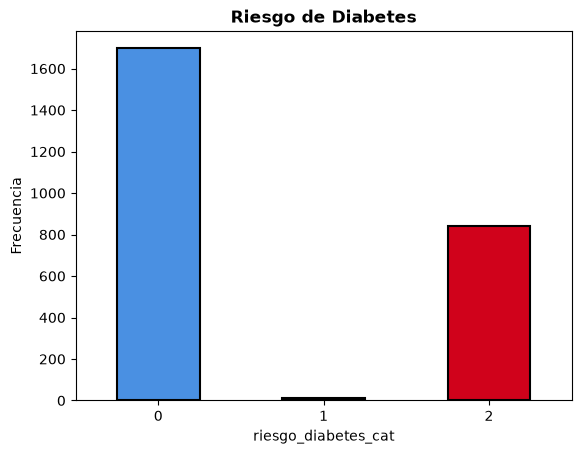

In [7]:
colores = ['#4A90E2', '#F5A623', '#D0021B']
ax = df['riesgo_diabetes_cat'].value_counts().sort_index().plot(
    kind='bar', color=colores, edgecolor='black', linewidth=1.5, rot=0
)
plt.title('Riesgo de Diabetes', fontweight='bold')
plt.ylabel('Frecuencia')
plt.show()

Vemos que en el riesgo moderado (1) hay solo 12 datos, a comparacion de las demas columnas, lo que provocará un problema de desbalance.

El problema de desbalance arruina el modelo porque la función de pérdida optimiza el acierto global y esas 12 muestras tienen un peso casi nulo en el gradiente, lo que hace que el algoritmo aprenda a ignorarla. Además, que estadísticamente es imposible calcular una frontera de decisión válida con tan pocos puntos, lo que genera un sobreajuste total.

In [8]:
df.isnull().sum()  # El numero de datos faltantes en cada columna

folio_i                   0
folio_int                 0
sexo                      0
edad                     25
Ciudad                    0
Peso                    720
Estatura                720
imc                    2514
muestra_suero             0
ac_urico                  0
albu                      0
col_hdl                   0
col_ldl                   0
colest                    0
creat                     0
glu_suero                 0
insulina                  0
trig                      0
hb1ac                  2308
ponde_venosa             99
estrato                   0
est_sel                   0
ponde_hemo              980
riesgo_diabetes_cat       0
dtype: int64

Hay gran cantidad de datos faltantes en el IMC y la hemoglobina glucosilada, tambien en el pondedador de muestra de hemoglobina y el peso y la estatura.

In [9]:
duplicados = df.duplicated().sum()  # Verificar si hay duplicados en el dataset
print(f"Filas duplicadas: {duplicados}")

Filas duplicadas: 0


## **Transformación de los datos categóricos**

En la visualización de los datos, notamos que hay columnas las cuales son clasificadas como categóricas, pero en realidad son numéricas, esto debido a que en los decimales en lugar de un punto, hay una coma, lo que hace que pandas lo clasifique como categórico.

In [10]:
columnas_a_limpiar = ['Peso', 'Estatura', 'ac_urico', 'albu', 'col_hdl', 'creat', 'insulina', 'ponde_venosa', 'ponde_hemo']
# Las columnas clasificadas como categoricas pero en realidad son numericas, vamos a limpiarlas reemplazandoles la , por un .
for col in columnas_a_limpiar:
    if col in df.columns:
        # Reemplazamos comas por puntos y convertimos a valores numericos
        df[col] = df[col].astype(str).str.replace(',', '.')
        df[col] = pd.to_numeric(df[col], errors='coerce')

print(df[columnas_a_limpiar].dtypes)

Peso            float64
Estatura        float64
ac_urico        float64
albu            float64
col_hdl         float64
creat           float64
insulina        float64
ponde_venosa    float64
ponde_hemo      float64
dtype: object


## **Analisis Exploratorio de los Datos**

Con los datos ya transformados, podemos ver mejor la distribucion de las columnas importantes, para verificar que no hayan valores atipicos o comportamientos extraños.

**Columna de edad**

In [11]:
df['edad'].describe()

count    2524.000000
mean       35.763074
std       319.672846
min     -7975.000000
25%        34.000000
50%        47.500000
75%        62.000000
max        95.000000
Name: edad, dtype: float64

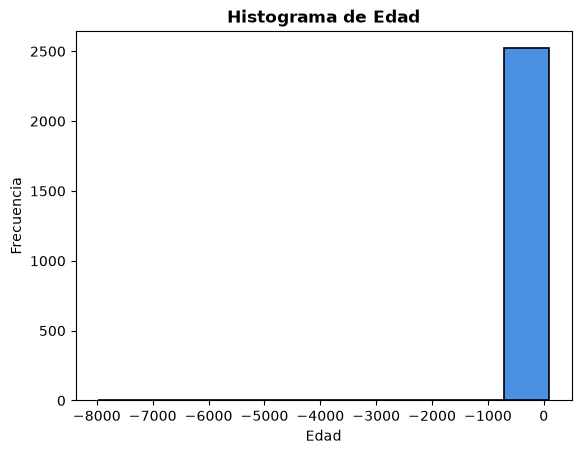

In [12]:
df['edad'].hist(color='#4A90E2', edgecolor='black', linewidth=1.2, grid=False)
plt.title('Histograma de Edad', fontweight='bold')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()

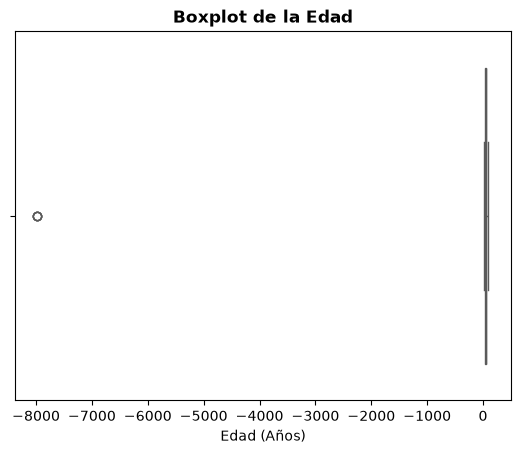

In [13]:
sns.boxplot(x=df['edad'], color='#4A90E2')
plt.title('Boxplot de la Edad', fontweight='bold')
plt.xlabel('Edad (Años)')
plt.show()

Analizando el boxplot y el histograma, podemos ver un comportamiento inusual en la columna de "Edad". Retomando lo que se habia presentado en la descripcion del dataset, se habia observado en el valor minimo de la columna un valor de -7975, lo que esta ocasionando que las graficas se distorsionen. Para poder visualizar mejor la distribucion de la columna, tendremos que eliminar el valor atipico.

Filtraremos los datos que quedan fuera de los bigotes del boxplot, utilizando el IQR (rango intercuartilico), para que descarte valores atipicos en la columna.

In [14]:
Q1 = df['edad'].quantile(0.25)
Q3 = df['edad'].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

In [15]:
df_filtrado = df[(df['edad'] >= limite_inferior) & (df['edad'] <= limite_superior)]

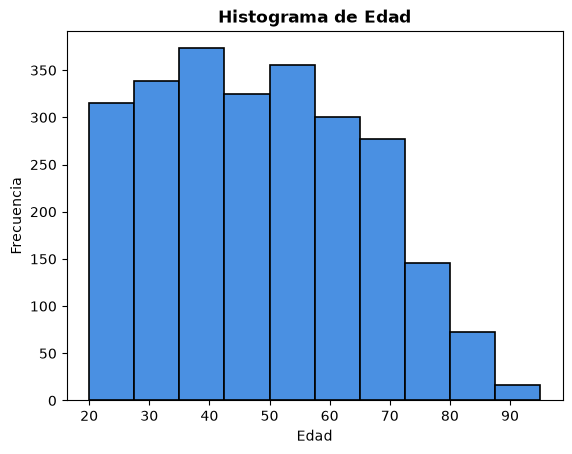

In [16]:
df_filtrado['edad'].hist(color='#4A90E2', edgecolor='black', linewidth=1.2, grid=False)
plt.title('Histograma de Edad', fontweight='bold')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()

El histograma de edad muestra un comportamiento de una distribución Gamma (desplazada o truncada a partir de los 20 años), caracterizada por una marcada asimetría positiva o sesgo hacia la derecha. La mayor densidad de registros se concentra en las etapas de adultez joven y media para luego descender de forma gradual a partir de los 60 años y formar una cola alargada hacia las edades más avanzadas (de 70 a 95 años), donde la frecuencia disminuye progresivamente sin llegar a ser nula.

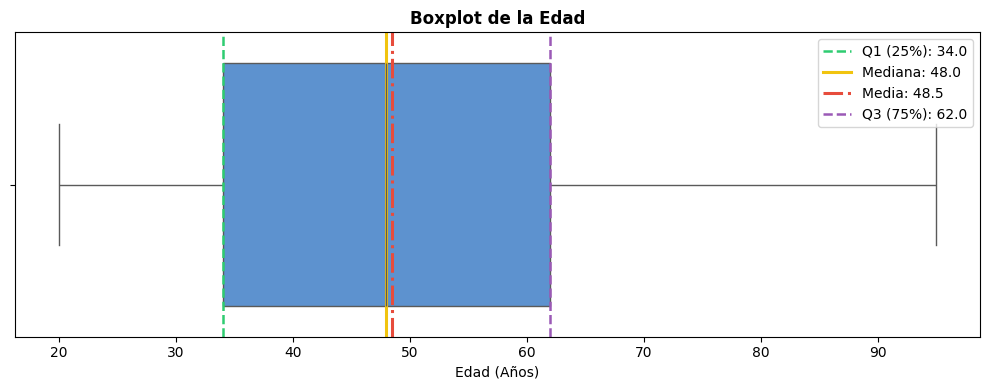

In [ ]:
datos = df_filtrado['edad']
media = df_filtrado['edad'].mean()
mediana = df_filtrado['edad'].median()
q1 = df_filtrado['edad'].quantile(0.25)
q3 = df_filtrado['edad'].quantile(0.75)

plt.figure(figsize=(10, 4))
sns.boxplot(x=datos, color='#4A90E2')

plt.axvline(q1, color='#2ECC71', linestyle='--', linewidth=1.8, label=f'Q1 (25%): {q1:.1f}')
plt.axvline(mediana, color='#F1C40F', linestyle='-', linewidth=2.2, label=f'Mediana: {mediana:.1f}')
plt.axvline(media, color='#E74C3C', linestyle='-.', linewidth=2.2, label=f'Media: {media:.1f}')
plt.axvline(q3, color='#9B59B6', linestyle='--', linewidth=1.8, label=f'Q3 (75%): {q3:.1f}')

plt.title('Boxplot de la Edad', fontweight='bold')
plt.xlabel('Edad (Años)')
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

**Columna de peso y Estatura**

In [17]:
df['Peso'].describe()

count    1829.000000
mean       76.646528
std        21.037884
min        31.700000
25%        63.650000
50%        73.750000
75%        86.100000
max       222.220000
Name: Peso, dtype: float64

In [18]:
df['Estatura'].describe()

count    1829.000000
mean      159.751011
std        11.088696
min       126.500000
25%       152.500000
50%       158.800000
75%       165.600000
max       222.200000
Name: Estatura, dtype: float64

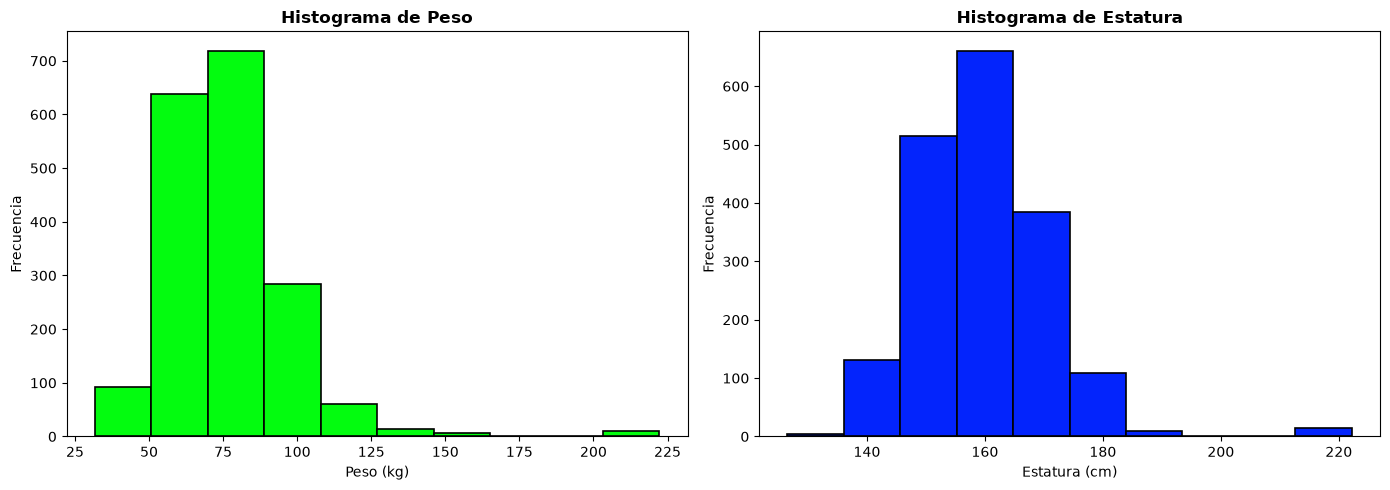

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de Peso
axes[0].hist(df['Peso'], color='#03fc0f', edgecolor='black', linewidth=1.2)
axes[0].set_title('Histograma de Peso', fontweight='bold')
axes[0].set_xlabel('Peso (kg)')
axes[0].set_ylabel('Frecuencia')

# Histograma de Estatura
axes[1].hist(df['Estatura'], color='#0324fc', edgecolor='black', linewidth=1.2)
axes[1].set_title('Histograma de Estatura', fontweight='bold')
axes[1].set_xlabel('Estatura (cm)')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

En la columna del peso, se observa un comportamiento mas "normal" a comparacion de la columna de edad, pues no hay valores atipicos tan extremos.

Se observa una distribucion con asimetria positiva (sesgada hacia la derecha), lo que indica que hay valores altos que alargan la cola, esto debido a que la media es mayor que la mediana. De igual manera, presenta demasiados outliers, asi que debemos verlos a mas profundidad para determinar a que se deben.

Con la columna de Estatura, presenta tambien una asimetria positiva, indicando la presencia de outliers que estiran la cola hacia la derecha. Hay menos valores atipicos, pero algo a notar es que en el valor de 220 aproximadamente hay mas valores atipicos, este comportamiento tambien habia aparecido en la columna de Peso, asi que debemos verificar que estos valores sean normales.

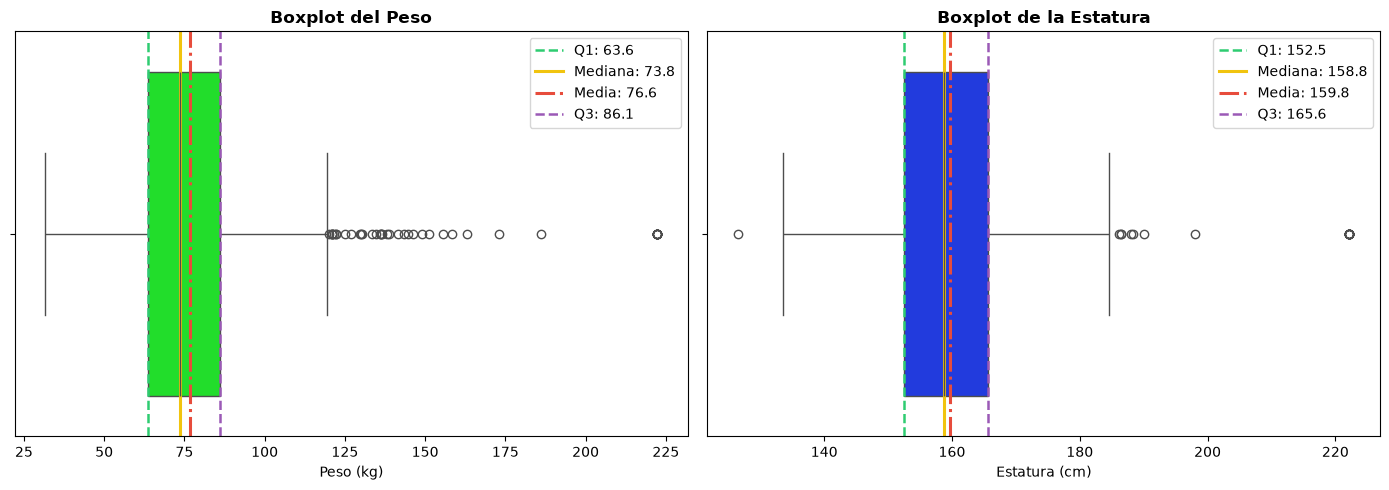

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

def graficar_boxplot_con_stats(ax, serie, color, titulo, xlabel):
    media = serie.mean()
    mediana = serie.median()
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)

    sns.boxplot(x=serie, color=color, ax=ax)

    ax.axvline(q1, color='#2ECC71', linestyle='--', linewidth=1.8, label=f'Q1: {q1:.1f}')
    ax.axvline(mediana, color='#F1C40F', linestyle='-', linewidth=2.2, label=f'Mediana: {mediana:.1f}')
    ax.axvline(media, color='#E74C3C', linestyle='-.', linewidth=2.2, label=f'Media: {media:.1f}')
    ax.axvline(q3, color='#9B59B6', linestyle='--', linewidth=1.8, label=f'Q3: {q3:.1f}')

    ax.set_title(titulo, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.legend(loc='upper right', frameon=True)

graficar_boxplot_con_stats(axes[0], df['Peso'], '#03fc0f', 'Boxplot del Peso', 'Peso (kg)')
graficar_boxplot_con_stats(axes[1], df['Estatura'], '#0324fc', 'Boxplot de la Estatura', 'Estatura (cm)')

plt.tight_layout()
plt.show()

**Analisis de valores atipicos del Peso**

Vamos a examinar los valores mas altos de la variable Peso para determinar si son biologicamente posibles o si son errores.

In [21]:
# Analizar los percentiles mas altos de la variable Peso
print("Percentiles del Peso (kg):")
display(df['Peso'].quantile([0.90, 0.95, 0.98, 0.99, 0.995, 1.0]))

# Mostrar los registros con los 10 pesos mas altos detectados
display(df[['sexo', 'edad', 'Estatura', 'Peso', 'imc', 'riesgo_diabetes_cat']].nlargest(10, 'Peso'))

Percentiles del Peso (kg):


0.900     98.880
0.950    108.000
0.980    121.904
0.990    145.722
0.995    222.220
1.000    222.220
Name: Peso, dtype: float64

,sexo,edad,Estatura,Peso,imc,riesgo_diabetes_cat
91,Hombre,45.0,222.2,222.22,NaN,2
119,Mujer,47.0,222.2,222.22,NaN,2
136,Hombre,56.0,222.2,222.22,NaN,0
163,Hombre,47.0,222.2,222.22,NaN,2
254,Mujer,24.0,222.2,222.22,NaN,0
419,Hombre,55.0,222.2,222.22,NaN,0
1020,Hombre,59.0,222.2,222.22,NaN,2
1021,Hombre,21.0,222.2,222.22,NaN,0
1043,Hombre,39.0,222.2,222.22,NaN,0
1727,Hombre,50.0,222.2,222.22,NaN,0


**Corrección de Valores Placeholder**

Identificamos que el valor 222.22 en peso y 222.2 en estatura son placeholders del set de datos. Vamos a eliminarlos.

In [22]:
# Filtramos el DataFrame original para eliminar directamente las filas con los placeholders
# nos quedamos con las filas que NO tienen 222.22 en Peso Y tampoco tienen 222.2 en Estatura
df = df[(df['Peso'] != 222.22) & (df['Estatura'] != 222.2)]

In [23]:
df['Peso'].describe()  # Nuevas medidas de la variable de peso

count    1814.000000
mean       75.756604
std        17.790150
min        31.700000
25%        63.562500
50%        73.600000
75%        85.937500
max       186.000000
Name: Peso, dtype: float64

In [24]:
df['Estatura'].describe()  # Nuevas medidas de la variable de estatura

count    1814.000000
mean      159.234620
std         9.562623
min       126.500000
25%       152.400000
50%       158.650000
75%       165.500000
max       198.000000
Name: Estatura, dtype: float64

## **Matriz de Correlacion**

Ya que tenemos las columnas numericas listas para ser analizadas (sin valores atipicos o valores nulos), observaremos la matriz de correlacion para determinar cuales variables son las mas importantes para nuestra variable objetivo, y tambien, observar si no hay multicolinealidad entre variables.

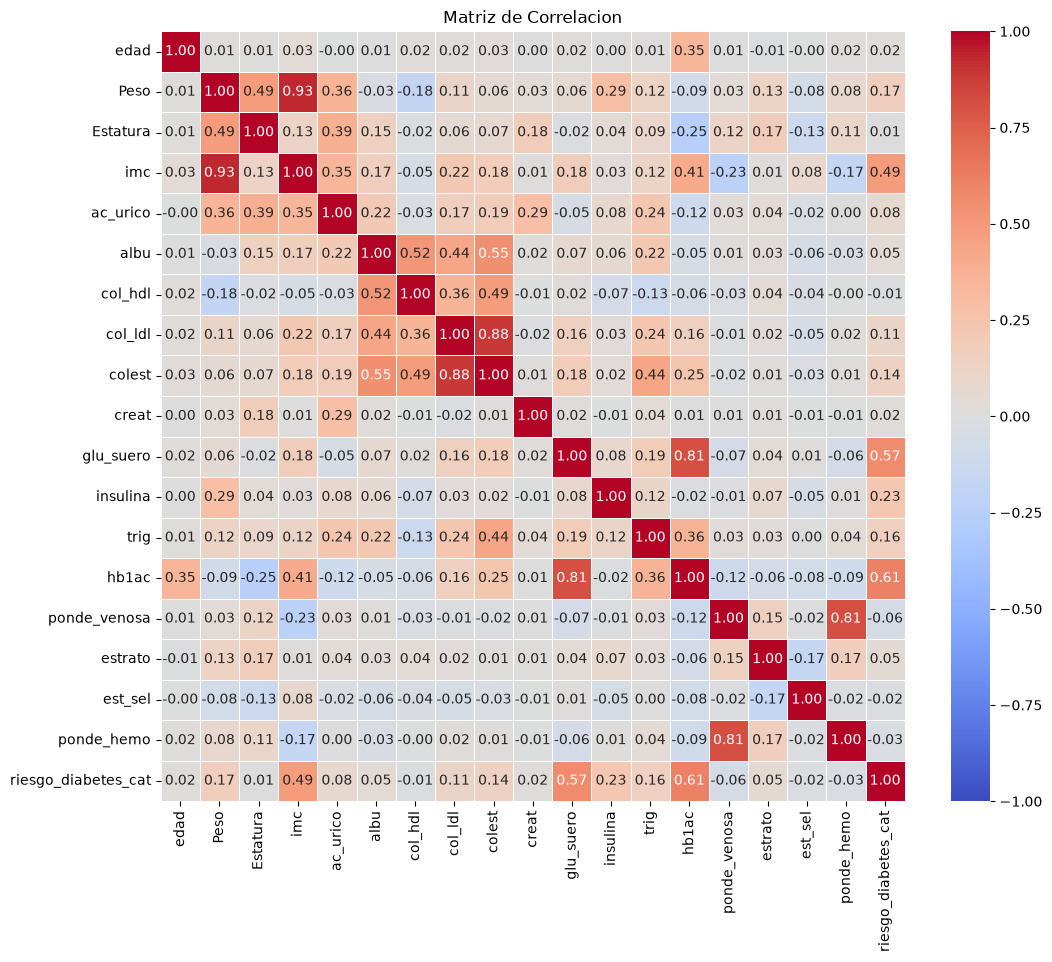

In [25]:
columnas_numericas = df.select_dtypes(include=['float64', 'int64']).columns
columnas_finales = [col for col in columnas_numericas if col != 'muestra_suero'] # Se excluye la muestra del suero pues es una constante (sin variabilidad) y no aporta informacion

matriz = df[columnas_finales].corr()  # Matriz de correlacion entre todas las variables para observar relaciones y detectar multicolinealidad

plt.figure(figsize=(12,10))
sns.heatmap(
    matriz,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)
plt.title("Matriz de Correlacion")
plt.savefig("matriz_correlacion.pdf", format="pdf", bbox_inches="tight")
plt.show()

Hay cierta correlacion entre las variables del ponderador por muestra venosa y el ponderador por muestra de hemoglobina (0.81).

Entre el IMC y el peso, hay correlacion muy alta (0.93) ya que el IMC es calculado en base al peso y la estatura

Entre las 3 variables de colesterol, tambien hay bastante correlacion entre ellas.

**Tomando en cuenta la variable objetivo del riesgo de diabetes, las variables que tienen mas correlacion con ella es la hemoglobina glucosilada, la concentracion de glucosa en suero y el IMC.**

**Justificacion:**

La hemoglobina glucosilada mide el promedio de azucar en la sangre de los ultimos 2 a 3 meses. Es el indicador diagnóstico más estable y confiable de hiperglucemia cronica; a mayor porcentaje, existe una certeza casi directa de la enfermedad.

La concentración de glucosa en suero refleja el nivel de azúcar circulando en el momento exacto de la toma. Dado que la diabetes se define clínicamente por la incapacidad del cuerpo para regular la glucosa (ya sea por falta de insulina o resistencia a ella), esta variable tiene una relación matemática y biológica directa con la etiqueta objetivo.

El Índice de Masa Corporal (IMC) es el principal factor de riesgo ambiental y metabólico. El exceso de tejido adiposo (especialmente visceral) libera ácidos grasos y moléculas inflamatorias que provocan resistencia a la insulina, el mecanismo previo que obliga al páncreas a fallar y dispara los niveles de glucosa.

In [26]:
df = df.drop(columns=['imc'], errors='ignore') # Eliminaremos la columa del IMC, pues tenian muchos datos faltantes, pero podemos calcularla con la estatura y el peso

In [27]:
df.info() # Informacion del dataset con las columnas eliminadas

<class 'pandas.DataFrame'>
Index: 2534 entries, 0 to 2548
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   folio_i              2534 non-null   str    
 1   folio_int            2534 non-null   str    
 2   sexo                 2534 non-null   str    
 3   edad                 2509 non-null   float64
 4   Ciudad               2534 non-null   str    
 5   Peso                 1814 non-null   float64
 6   Estatura             1814 non-null   float64
 7   muestra_suero        2534 non-null   float64
 8   ac_urico             2534 non-null   float64
 9   albu                 2534 non-null   float64
 10  col_hdl              2534 non-null   float64
 11  col_ldl              2534 non-null   float64
 12  colest               2534 non-null   float64
 13  creat                2534 non-null   float64
 14  glu_suero            2534 non-null   float64
 15  insulina             2534 non-null   float64
 16  trig

## **Calculo de la columna de IMC ya que fue eliminada**

El IMC puede ser calculado en base al peso y la estatura, asi que crearemos una nueva columna del IMC ya que habia sido eliminada por sus datos faltantes. A pesar de que la columna de peso y estatura tambien tenian cierta cantidad de datos faltantes, no eran tantos a comparacion del IMC, asi que lo mejor sera crear otra.

In [28]:
# Calcular el IMC a partir del Peso (kg) y la Estatura (cm)
df['imc'] = df['Peso'] / ((df['Estatura'] / 100) ** 2)

# Verificar cuantos valores validos de IMC tenemos ahora
print("Valores no nulos de IMC", df['imc'].notnull().sum())
df['imc']

Valores no nulos de IMC 1814


0             NaN
1             NaN
2       27.573188
3       24.834881
4             NaN
          ...    
2544          NaN
2545    33.299852
2546    30.600476
2547    29.681547
2548    28.434150
Name: imc, Length: 2534, dtype: float64

## **Filtro de edades atipicas**

Como habiamos observado en la exploracion de la columna de Edad, habia un outlier demasiado alto, asi que vamos a eliminarlo filtrando las edades, para que los modelos no tomen en cuenta el valor atipico.

In [29]:
# Filtrar edades atipicas, como se habia observado en el EDA, habia un valor atipico demasiado alto
df_limpio = df[(df['edad'] >= limite_inferior) & (df['edad'] <= limite_superior)]

# Comportamiento de la variable de hemoglobina glucosilada (hb1ac)

Como se habia visto en la matriz de correlacion, la hemoglobina glucosilada tenia gran correlacion con la variable objetivo, ya que mide el promedio de azucar en la sangre de los ultimos 2 a 3 meses; mientras más alto sea el porcentaje, mayor es la probabilidad de desarrollar diabetes.

Si bien, tiene gran importancia, tenia una gran cantidad de datos faltantes (2308). Entonces, para saber con que podemos imputar, observaremos sus valores por clase.

In [30]:
df[["riesgo_diabetes_cat","hb1ac"]].groupby(by="riesgo_diabetes_cat").median()["hb1ac"]
# mediana de la hemoglobina por clase

riesgo_diabetes_cat
0    5.0
1    5.0
2    6.0
Name: hb1ac, dtype: float64

Se puede observar que tanto en la clase 0 (bajo riesgo) y 1 (riesgo moderado, aunque solo habian 12 datos en total de este), la mediana de la hemoglobina glucosilada es de 5, mientras que del alto riesgo es 6. Observando esta clara diferencia, podremos imputar con la mediana de cada clase los valores faltantes, asi, garantiza que el algoritmo aprenda una frontera clara (5 para bajo riesgo y 6 para alto).

Se eligio la mediana ya que, el nivel de hb1ac se mantiene sumamente estable en personas sanas (generalmente alrededor de 5.0%), pero se dispara significativamente con la presencia de hiperglucemia crónica en pacientes de alto riesgo. Si utilizáramos la media matemática para la imputación, estaríamos introduciendo un valor promedio sesgado por los extremos más altos de la población enferma, lo que artificialmente elevaría el nivel de HbA1c de personas sanas y debilitaria la diferencia real entre sanos y enfermos.

Al imputar con la mediana específica de cada categoría de riesgo, conservamos la naturaleza discreta y biológica de la variable.

In [31]:
df[["riesgo_diabetes_cat","hb1ac"]][df["riesgo_diabetes_cat"] == 0].dropna()["hb1ac"].unique() # Valores unicos de hb1ac

array([5.])

## **Imputacion y procesamiento**

Ya que tenemos las columnas conflictivas por la matriz de correlacion eliminadas y el filtro de la edad hecho, podemos empezar con la imputacion y rellenar los valores nulos de las columnas.

Primero, uniremos las columnas del riesgo de diabetes de moderado y alto, esto debido a que como se habia observado anteriormente, el riesgo de diabetes moderado solo tenia 12 datos en total, haciendo un problema de desbalance y afectando a los modelos (ya que al haber tan poca cantidad, los modelos no predeciran esta variable). Uniendo las columnas, ahora podemos clasificar si una persona tiene riesgo de diabetes o no (binario)

Descartaremos las columnas que no aportan informacion (el folio y la muestra de suero). La muestra de suero fue descartada debido a que no habia variacion.

Se decidió eliminar el ponderador de muestra venosa y conservar únicamente el ponderador de muestra de hemoglobina debido a la alta multicolinealidad detectada entre ambas variables (0.83). Mantener dos predictores altamente colineales introduce redundancia de información, lo que infla la varianza de los coeficientes (en modelos lineales) o diluye la importancia real de las características (en modelos basados en árboles). La selección del ponderador de hemoglobina sobre el de muestra venosa responde a un criterio de especificidad metodológica y clínica: dado que la hemoglobina glucosilada es el biomarcador más estable y determinante en la definición del riesgo de diabetes (al reflejar el comportamiento glucémico crónico de los últimos meses y no solo una medición puntual).


In [32]:
# Imputacion de 'hb1ac' por la mediana de su clase original ('riesgo_diabetes_cat')
# calculamos la mediana de 'hb1ac' para cada clase (0, 1, 2) del dataframe
medianas_por_clase = df_limpio.groupby('riesgo_diabetes_cat')['hb1ac'].median()
print("Medianas de hb1ac por clase original:")
print(medianas_por_clase)

# Imputamos los nulos de 'hb1ac' basándonos en el grupo correspondiente
df_limpio['hb1ac'] = df_limpio.groupby('riesgo_diabetes_cat')['hb1ac'].transform(lambda x: x.fillna(x.median()))

# Fusionar las categorías de riesgo en el dataframe para el modelo binario
# 0 (Bajo riesgo), 1 y 2 -> 1 (Con riesgo)
df_limpio['riesgo_diabetes_cat'] = df_limpio['riesgo_diabetes_cat'].map({0: 0, 1: 1, 2: 1})

# Definir variables predictoras (X) y objetivo (y)
columnas_descartar = ['folio_i', 'folio_int', 'riesgo_diabetes_cat', 'muestra_suero','ponde_hemo']
X = df_limpio.drop(columns=columnas_descartar, errors='ignore')
y = df_limpio['riesgo_diabetes_cat']

numerical_cols = X.select_dtypes(include=['float64', 'int64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()

# Procesamiento
X_modificado = X.copy()

# Procesamiento de variables numéricas
for col in numerical_cols:
    # Imputación con la mediana (para el resto de las columnas con nulos, como Peso/Estatura/imc)
    median_val = X_modificado[col].median()
    X_modificado[col] = X_modificado[col].fillna(median_val)

    # Estandarización
    mean_val = X_modificado[col].mean()
    std_val = X_modificado[col].std(ddof=0)  # Desviación estándar poblacional
    if std_val != 0:
        X_modificado[col] = (X_modificado[col] - mean_val) / std_val

# Procesamiento de variables categóricas
for col in categorical_cols:
    # Imputación con la moda
    if not X_modificado[col].mode().empty:
        moda_val = X_modificado[col].mode()[0]
        X_modificado[col] = X_modificado[col].fillna(moda_val)

# Codificación One-Hot
X_modificado = pd.get_dummies(X_modificado, columns=categorical_cols, dtype=float)

Medianas de hb1ac por clase original:
riesgo_diabetes_cat
0    5.0
1    5.0
2    6.0
Name: hb1ac, dtype: float64


C:\Users\someo\AppData\Local\Temp\ipykernel_25900\449836853.py:20: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=['object']).columns.tolist()


In [33]:
# Resultado en forma de matriz
X_numpy = X_modificado.to_numpy()

print("\nForma final de la matriz de predictores X:", X_numpy.shape) # Comprobar el tamaño de la matriz
X_modificado.head() # Visualizar el dataframe transformado y limpio


Forma final de la matriz de predictores X: (2505, 286)


,edad,Peso,Estatura,ac_urico,albu,col_hdl,col_ldl,colest,creat,glu_suero,...,Ciudad_YAHUALICA,Ciudad_YANGA,Ciudad_YAUTEPEC,Ciudad_YAXCAB,Ciudad_ZACAPOAXTLA,Ciudad_ZACATECAS,Ciudad_ZACATELCO,Ciudad_ZACATEPEC,Ciudad_ZAPOPAN,Ciudad_ZITCUARO
0,2.375494,-0.101370,-0.049768,-0.566672,-0.549661,0.335952,0.128102,-0.212916,-0.223102,1.167613,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.319880,-0.101370,-0.049768,-0.427851,0.620889,1.458183,1.632921,1.598735,-0.183037,-0.144109,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.498847,0.331969,1.418224,-0.011388,1.289775,3.422086,-1.376718,0.234115,-0.263167,0.434592,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-1.671026,-0.438779,0.875437,-0.011388,1.624218,2.767451,-0.841671,0.375282,-0.203069,0.125951,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.495816,-0.101370,-0.049768,1.029769,0.955332,2.393374,1.699802,2.045766,0.718432,-0.163399,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#**Algoritmos**

##Funciones

In [ ]:
"""
def gradient_descent(grad_fn, x0, learning_rate=0.1, n_iterations=100):
    x = np.array(x0, dtype=float)
    for _ in range(n_iterations):
        x = x - learning_rate * grad_fn(x)
    return x


def train_test_split(X, y, test_size=0.25, seed=0):
    rng = np.random.default_rng(seed)
    indices = rng.permutation(len(X))
    n_test = int(round(len(X) * test_size))
    test_idx, train_idx = indices[:n_test], indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

def standardize(X):
    mean = X.mean(axis=0)
    std = X.std(axis=0)
    std = np.where(std == 0, 1.0, std)
    return (X - mean) / std, mean, std

def k_fold_indices(n_samples, k=5, seed=0):
    rng = np.random.default_rng(seed)
    indices = rng.permutation(n_samples)
    folds = np.array_split(indices, k)
    splits = []
    for i in range(k):
        train_idx = np.concatenate([folds[j] for j in range(k) if j != i])
        splits.append((train_idx, folds[i]))
    return splits

def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def mean_absolute_error(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_counts(y_true, y_pred):
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    return tp, fp, fn, tn

def precision_recall_f1(y_true, y_pred):
    tp, fp, fn, tn = confusion_counts(y_true, y_pred)
    precision = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
    return precision, recall, f1
"""

##Split

In [34]:
y_numpy = y.to_numpy()
X_train, X_test, y_train, y_test = fn.train_test_split(X_numpy, y_numpy, test_size=0.20, seed=0)

##Regresión logística

In [ ]:

"""
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def predict_proba(self, X):
        return self._sigmoid(X.dot(self.weights) + self.bias)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    def compute_cost(self, X, y):
        eps = 1e-15
        p = np.clip(self.predict_proba(X), eps, 1 - eps)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

    def compute_gradients(self, X, y):
        n_samples = X.shape[0]
        errors = self.predict_proba(X) - y
        dw = (1 / n_samples) * X.T.dot(errors)
        db = (1 / n_samples) * np.sum(errors)
        return dw, db

    def fit(self, X, y):
        n_features = X.shape[1]
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        for _ in range(self.n_iterations):
            dw, db = self.compute_gradients(X, y)
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db
        return self

###RLog. - Entrenamiento

In [35]:
modelo_log = fn.LogisticRegression(learning_rate=0.5, n_iterations=1500)

times_log_train = []

start_time = time.perf_counter()
modelo_log.fit(X_train, y_train)
end_time = time.perf_counter()
times_log_train.append(end_time - start_time)

predicciones_train = modelo_log.predict(X_train, threshold=0.35)
error = modelo_log.compute_cost(X_train, y_train)
precision = fn.accuracy(y_train, predicciones_train)

print(f"Entropía cruzada binaria en el entrenamiento: {error:.4f}")
print(f"Precisión en el conjunto de entrenamiento: {precision*100:.2f}%")
print(f"Tiempo de entrenamiento: {times_log_train[-1]:.2f} segundos")


Entropía cruzada binaria en el entrenamiento: 0.0431
Precisión en el conjunto de entrenamiento: 98.90%
Tiempo de entrenamiento: 1.73 segundos


Precisión: 100.00%
Sensibilidad (Recall): 96.81%
F1-Score: 98.38%


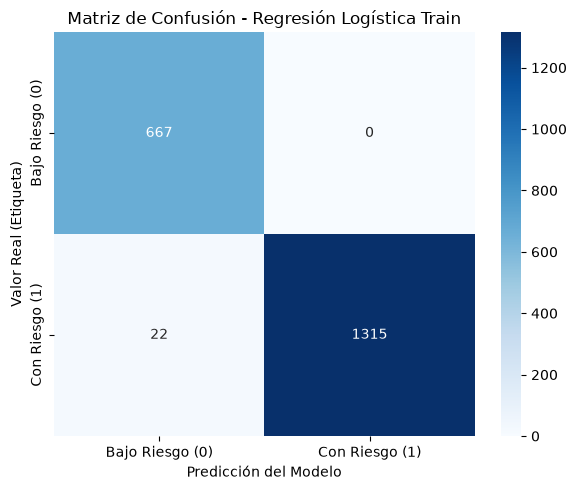

In [36]:
precision, recall, f1 = fn.precision_recall_f1(y_train, predicciones_train)
print(f"Precisión: {precision*100:.2f}%")
print(f"Sensibilidad (Recall): {recall*100:.2f}%")
print(f"F1-Score: {f1*100:.2f}%")

tn, fp, fn, tp = fn.confusion_counts(y_train, predicciones_train)

#Graficar Matriz de confusion
matriz_confusion = np.array([[tn, fp],
                             [fn, tp]])

plt.figure(figsize=(6, 5))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Bajo Riesgo (0)', 'Con Riesgo (1)'],
            yticklabels=['Bajo Riesgo (0)', 'Con Riesgo (1)'])
plt.title('Matriz de Confusión - Regresión Logística Train')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real (Etiqueta)')
plt.tight_layout()
plt.show()

###RLog. - Prueba

In [39]:
times_log_pred = []

start_time = time.perf_counter()
predicciones_test = modelo_log.predict(X_test, threshold=0.35)
end_time = time.perf_counter()
times_log_pred.append(end_time - start_time)

error_final = modelo_log.compute_cost(X_test, y_test)
precision_final = fn.accuracy(y_test, predicciones_test)

print(f"Entropía cruzada binaria en el conjunto de prueba: {error_final:.4f}")
print(f"Precisión en el conjunto de prueba: {precision_final*100:.2f}%")
print(f"Tiempo de predicción: {times_log_pred[-1]:f} segundos")

Entropía cruzada binaria en el conjunto de prueba: 0.0445
Precisión en el conjunto de prueba: 99.00%
Tiempo de predicción: 0.002551 segundos


Precisión: 100.00%
Sensibilidad (Recall): 96.60%
F1-Score: 98.27%


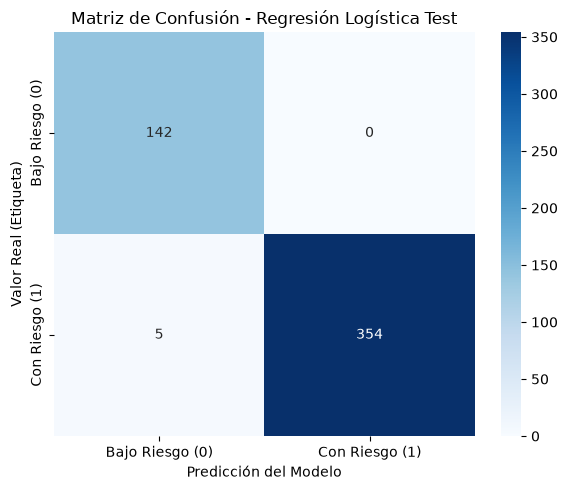

In [40]:
precision, recall, f1 = fn.precision_recall_f1(y_test, predicciones_test)
print(f"Precisión: {precision*100:.2f}%")
print(f"Sensibilidad (Recall): {recall*100:.2f}%")
print(f"F1-Score: {f1*100:.2f}%")

tn, fp, fn, tp = fn.confusion_counts(y_test, predicciones_test)

#Graficar Matriz de confusion
matriz_confusion = np.array([[tn, fp],
                             [fn, tp]])

plt.figure(figsize=(6, 5))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Bajo Riesgo (0)', 'Con Riesgo (1)'],
            yticklabels=['Bajo Riesgo (0)', 'Con Riesgo (1)'])
plt.title('Matriz de Confusión - Regresión Logística Test')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real (Etiqueta)')
plt.tight_layout()
plt.show()

###RLog. - Tiempo asintótico

In [42]:
!pip install big_o

  Using cached big_o-0.11.0-py3-none-any.whl


La complejidad asintótica estimada es: Linear: time = 0.027 + 6.2E-05*n (sec)


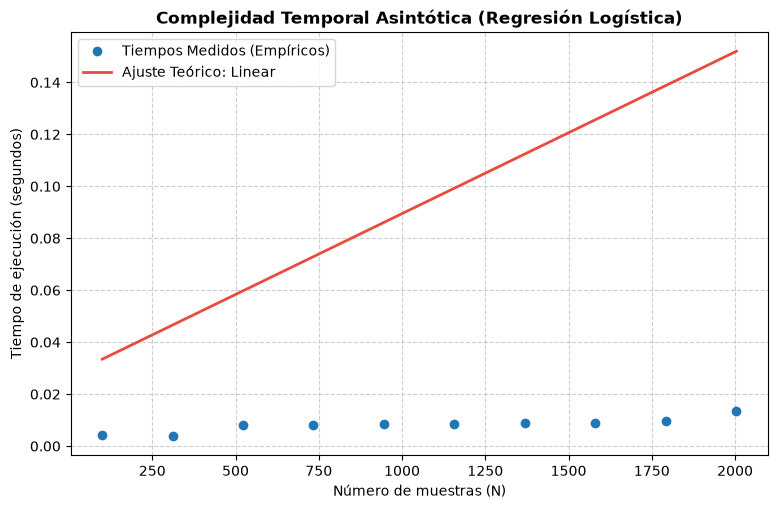

In [46]:
import big_o # Librería que determina la clase de complejidad que mejor se ajusta

# Función destinada a deducir la complejidad asintótica
# Esta función entrena el modelo de regresión logística con un subconjunto de tamaño n
def benchmark_logistic_regression(n):
    X_sub = X_train[:n]
    y_sub = y_train[:n]

    # Inicialización
    modelo = fn.LogisticRegression(learning_rate=0.5, n_iterations=10)
    modelo.fit(X_sub, y_sub)
    modelo.predict(X_sub, threshold=0.35)

# Generador de datos para que big_o deduzca la complejidad
def data_generator(n):
    return n

# Rangos de N para las mediciones
min_n = 100
max_n = len(X_train)

# Calculamos la complejidad asintótica con big_o
best_fitting, fitted_complexities = big_o.big_o(
    benchmark_logistic_regression,
    data_generator,
    min_n=min_n,
    max_n=max_n,
    n_measures=30,
    n_repeats=10
)

print(f"La complejidad asintótica estimada es: {best_fitting}")

# Graficamos los tiempos medidos reales y la curva teórica del mejor ajuste
ns = np.linspace(min_n, max_n, 10, dtype=int)
tiempos_medidos = []

# Medimos tiempos promedio manualmente para graficarlos de forma precisa
# Se promedian 3 tiempos
for n in ns:
    tiempos_n = []
    for _ in range(3):
        inicio = time.perf_counter()
        benchmark_logistic_regression(n)
        tiempos_n.append(time.perf_counter() - inicio)
    tiempos_medidos.append(np.mean(tiempos_n))

# Se reconstruyen los puntos teóricos pasando directamente todo ns
tiempos_estimados = best_fitting.compute(ns)

plt.figure(figsize=(9, 5.5))
plt.plot(ns, tiempos_medidos, 'o', label='Tiempos Medidos (Empíricos)', color='#1F77B4')
plt.plot(ns, tiempos_estimados, '-', label=f'Ajuste Teórico: {best_fitting.__class__.__name__}', color='#E74C3C', linewidth=2)
plt.xlabel('Número de muestras (N)')
plt.ylabel('Tiempo de ejecución (segundos)')
plt.title('Complejidad Temporal Asintótica (Regresión Logística)', fontweight='bold')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

##KNN

In [ ]:
"""

from collections import Counter


class KNNClassifier:
    def __init__(self, n_neighbors=3):
        self.n_neighbors = n_neighbors
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
        return self

    def _euclidean_distance(self, a, b):
        return np.sqrt(np.sum((a - b) ** 2))

    def _predict_one(self, x):
        distances = np.array([self._euclidean_distance(x, x_train) for x_train in self.X_train])
        nearest_indices = np.argsort(distances)[:self.n_neighbors]
        nearest_labels = self.y_train[nearest_indices]
        return Counter(nearest_labels.tolist()).most_common(1)[0][0]

    def predict(self, X):
        return np.array([self._predict_one(x) for x in X])


###KNN - Entrenamiento

In [52]:
modelo_knn = fn.KNNClassifier(n_neighbors=7)

times_knn_train = []
start_time = time.perf_counter()

modelo_knn.fit(X_train, y_train)

end_time = time.perf_counter()
times_knn_train.append(end_time - start_time)

times_knn_predtr = []
start_time = time.perf_counter()
predicciones_train = modelo_knn.predict(X_train)
end_time = time.perf_counter()
times_knn_predtr.append(end_time - start_time)

precision = fn.accuracy(y_train, predicciones_train)

print(f"Precisión en el conjunto de entrenamiento: {precision*100:.2f}%")
print(f"Tiempo de entrenamiento: {times_knn_train[-1]:f} segundos")
print(f"Tiempo de predicción: {times_knn_predtr[-1]:f} segundos")

Precisión en el conjunto de entrenamiento: 96.91%
Tiempo de entrenamiento: 0.000153 segundos
Tiempo de predicción: 78.575311 segundos


Precisión: 99.68%
Sensibilidad (Recall): 91.29%
F1-Score: 95.30%


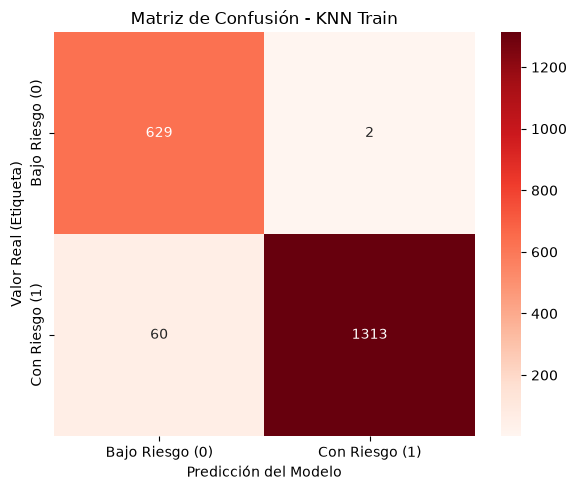

In [53]:
precision, recall, f1 = fn.precision_recall_f1(y_train, predicciones_train)
print(f"Precisión: {precision*100:.2f}%")
print(f"Sensibilidad (Recall): {recall*100:.2f}%")
print(f"F1-Score: {f1*100:.2f}%")

tn, fp, fn, tp = fn.confusion_counts(y_train, predicciones_train)

#Graficar Matriz de confusion
matriz_confusion = np.array([[tn, fp],
                             [fn, tp]])

plt.figure(figsize=(6, 5))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Bajo Riesgo (0)', 'Con Riesgo (1)'],
            yticklabels=['Bajo Riesgo (0)', 'Con Riesgo (1)'])
plt.title('Matriz de Confusión - KNN Train')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real (Etiqueta)')
plt.tight_layout()
plt.show()

###KNN - Prueba

In [57]:
times_knn_pred = []
start_time = time.perf_counter()

predicciones_test = modelo_knn.predict(X_test)

end_time = time.perf_counter()
times_knn_pred.append(end_time - start_time)

precision = fn.accuracy(y_test, predicciones_test)

print(f"Precisión en el conjunto de prueba: {precision*100:.2f}%")
print(f"Tiempo de predicción: {times_knn_pred[-1]:f} segundos")

Precisión en el conjunto de prueba: 95.41%
Tiempo de predicción: 18.265201 segundos


Precisión: 99.21%
Sensibilidad (Recall): 85.03%
F1-Score: 91.58%


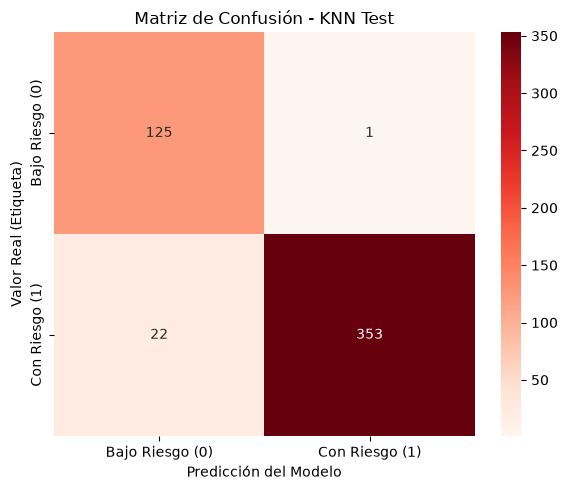

In [58]:
precision, recall, f1 = fn.precision_recall_f1(y_test, predicciones_test)
print(f"Precisión: {precision*100:.2f}%")
print(f"Sensibilidad (Recall): {recall*100:.2f}%")
print(f"F1-Score: {f1*100:.2f}%")

tn, fp, fn, tp = fn.confusion_counts(y_test, predicciones_test)

#Graficar Matriz de confusion
matriz_confusion = np.array([[tn, fp],
                             [fn, tp]])

plt.figure(figsize=(6, 5))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Bajo Riesgo (0)', 'Con Riesgo (1)'],
            yticklabels=['Bajo Riesgo (0)', 'Con Riesgo (1)'])
plt.title('Matriz de Confusión - KNN Test')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real (Etiqueta)')
plt.tight_layout()
plt.show()

###KNN - Tiempo asintótico

La complejidad asintótica estimada es: Quadratic: time = 0.054 + 3E-05*n^2 (sec)


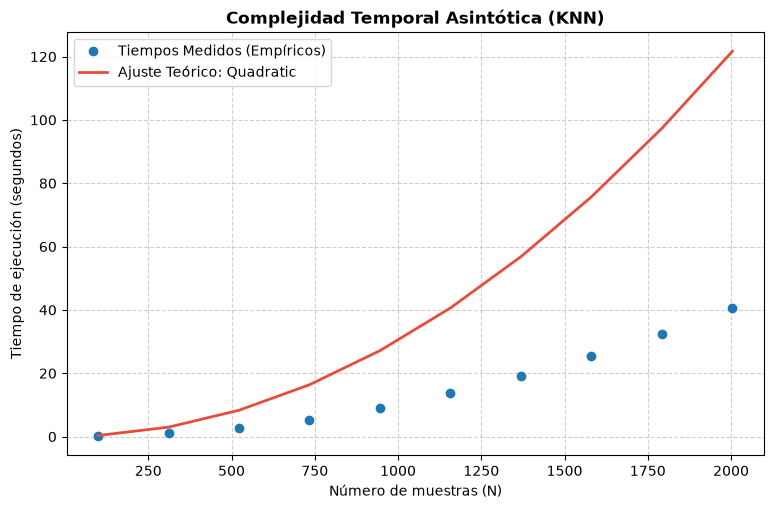

In [61]:
import big_o # Librería que determina la clase de complejidad que mejor se ajusta

# Función destinada a deducir la complejidad asintótica
# Esta función entrena el modelo de KNN con un subconjunto de tamaño n
def benchmark_KNNClassifier(n):
    X_sub = X_train[:n]
    y_sub = y_train[:n]

    # Inicialización
    modelo = fn.KNNClassifier(n_neighbors=7)
    modelo.fit(X_sub, y_sub)
    modelo.predict(X_sub)

# Generador de datos para que big_o deduzca la complejidad
def data_generator(n):
    return n

# Rangos de N para las mediciones
min_n = 100
max_n = len(X_train)

# Calculamos la complejidad asintótica con big_o
best_fitting, fitted_complexities = big_o.big_o(
    benchmark_KNNClassifier,
    data_generator,
    min_n=min_n,
    max_n=max_n,
    n_measures=10,
    n_repeats=3
)

print(f"La complejidad asintótica estimada es: {best_fitting}")

# Graficamos los tiempos medidos reales y la curva teórica del mejor ajuste
ns = np.linspace(min_n, max_n, 10, dtype=int)
tiempos_medidos = []

# Medimos tiempo manualmente para graficarlos de forma precisa
# Se usa un solo tiempo
for n in ns:
    tiempos_n = []
    for _ in range(1):
        inicio = time.perf_counter()
        benchmark_KNNClassifier(n)
        tiempos_n.append(time.perf_counter() - inicio)
    tiempos_medidos.append(np.mean(tiempos_n))

# Reconstruimos los puntos teóricos pasando directamente todo el array ns
tiempos_estimados = best_fitting.compute(ns)

plt.figure(figsize=(9, 5.5))
plt.plot(ns, tiempos_medidos, 'o', label='Tiempos Medidos (Empíricos)', color='#1F77B4')
plt.plot(ns, tiempos_estimados, '-', label=f'Ajuste Teórico: {best_fitting.__class__.__name__}', color='#E74C3C', linewidth=2)
plt.xlabel('Número de muestras (N)')
plt.ylabel('Tiempo de ejecución (segundos)')
plt.title('Complejidad Temporal Asintótica (KNN)', fontweight='bold')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

##Random Forest

In [ ]:
"""
class DecisionTreeClassifier:
    def __init__(self, max_depth=5, min_samples_split=2, max_features=None, rng=None):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.max_features = max_features
        self.rng = rng if rng is not None else np.random.default_rng(0)
        self.tree_ = None

    def _gini(self, y):
        proportions = np.bincount(y) / len(y)
        return 1 - np.sum(proportions ** 2)

    def _best_split(self, X, y):
        n_samples, n_features = X.shape
        features = np.arange(n_features)
        if self.max_features is not None:
            features = self.rng.choice(n_features, size=min(self.max_features, n_features), replace=False)
        best_feature, best_threshold, best_gini = None, None, np.inf
        for feature in features:
            for threshold in np.unique(X[:, feature]):
                mask = X[:, feature] <= threshold
                if mask.all() or not mask.any():
                    continue
                gini = (mask.sum() * self._gini(y[mask]) + (~mask).sum() * self._gini(y[~mask])) / n_samples
                if gini < best_gini:
                    best_feature, best_threshold, best_gini = feature, threshold, gini
        return best_feature, best_threshold

    def _build(self, X, y, depth):
        if len(np.unique(y)) == 1 or depth >= self.max_depth or len(y) < self.min_samples_split:
            return {'leaf': True, 'class': np.bincount(y).argmax()}
        feature, threshold = self._best_split(X, y)
        if feature is None:
            return {'leaf': True, 'class': np.bincount(y).argmax()}
        mask = X[:, feature] <= threshold
        return {'leaf': False, 'feature': feature, 'threshold': threshold,
                'left': self._build(X[mask], y[mask], depth + 1),
                'right': self._build(X[~mask], y[~mask], depth + 1)}

    def fit(self, X, y):
        self.tree_ = self._build(X, y, 0)
        return self

    def _predict_one(self, x, node):
        while not node['leaf']:
            node = node['left'] if x[node['feature']] <= node['threshold'] else node['right']
        return node['class']

    def predict(self, X):
        return np.array([self._predict_one(x, self.tree_) for x in X])

class RandomForestClassifier:
    def __init__(self, n_trees=25, max_depth=5, seed=0):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.seed = seed
        self.trees_ = []
        self.oob_indices_ = []
        self.n_classes_ = None

    def _bootstrap_sample(self, X, y, rng):
        n = len(X)
        indices = rng.integers(0, n, size=n)
        return X[indices], y[indices], indices

    def fit(self, X, y):
        rng = np.random.default_rng(self.seed)
        self.n_classes_ = int(y.max()) + 1
        max_features = max(1, int(np.sqrt(X.shape[1])))
        self.trees_ = []
        self.oob_indices_ = []
        for _ in range(self.n_trees):
            X_b, y_b, idx = self._bootstrap_sample(X, y, rng)
            tree = DecisionTreeClassifier(max_depth=self.max_depth, max_features=max_features, rng=rng)
            tree.fit(X_b, y_b)
            self.trees_.append(tree)
            self.oob_indices_.append(np.setdiff1d(np.arange(len(X)), idx))
        return self

    def predict(self, X):
        all_votes = np.array([tree.predict(X) for tree in self.trees_])
        return np.array([np.bincount(col, minlength=self.n_classes_).argmax() for col in all_votes.T])

    def oob_score(self, X, y):
        votes = np.zeros((len(X), self.n_classes_), dtype=int)
        for tree, oob in zip(self.trees_, self.oob_indices_):
            if len(oob) == 0:
                continue
            preds = tree.predict(X[oob])
            votes[oob, preds] += 1
        covered = votes.sum(axis=1) > 0
        return np.mean(votes[covered].argmax(axis=1) == y[covered])

In [ ]:
from sklearn.ensemble import RandomForestClassifier as SKRandomForest
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
# prueba con sklearn para ver la importancia de variables

# Obtener los nombres de las columnas resultantes tras el One-Hot Encoding
feature_names = X_modificado.columns

# Inicializar y entrenar el modelo de Random Forest con scikit-learn
rf_sk = SKRandomForest(n_estimators=100, max_depth=8, random_state=0)
rf_sk.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
y_pred_sk = rf_sk.predict(X_test)

# Evaluar el rendimiento
accuracy_sk = accuracy_score(y_test, y_pred_sk)
print(f"Exactitud del modelo (Scikit-Learn RF): {accuracy_sk * 100:.2f}%")
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred_sk))

Exactitud del modelo (Scikit-Learn RF): 99.40%

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       354
           1       1.00      0.98      0.99       147

    accuracy                           0.99       501
   macro avg       1.00      0.99      0.99       501
weighted avg       0.99      0.99      0.99       501



In [ ]:
# Obtener la importancia de las características directamente de las columnas de entrenamiento
# Dado que X_train es un numpy array, usaremos las primeras 286 columnas de X_modificado para mapear correctamente los nombres
importances = rf_sk.feature_importances_
features_used = X_modificado.columns[:len(importances)]

# Crear un DataFrame para organizar y visualizar los resultados de importancia
importancia_df = pd.DataFrame({
    'Característica': features_used,
    'Importancia': importances
}).sort_values(by='Importancia', ascending=False)

# Mostramos las 15 variables más importantes
print("Top 15 variables más importantes para el modelo:")
display(importancia_df.head(15))

Top 15 variables más importantes para el modelo:


,Característica,Importancia
12,hb1ac,0.377993
9,glu_suero,0.364954
0,edad,0.040969
10,insulina,0.030563
11,trig,0.024340
16,imc,0.023341
1,Peso,0.020520
3,ac_urico,0.010448
2,Estatura,0.010297
6,col_ldl,0.010186


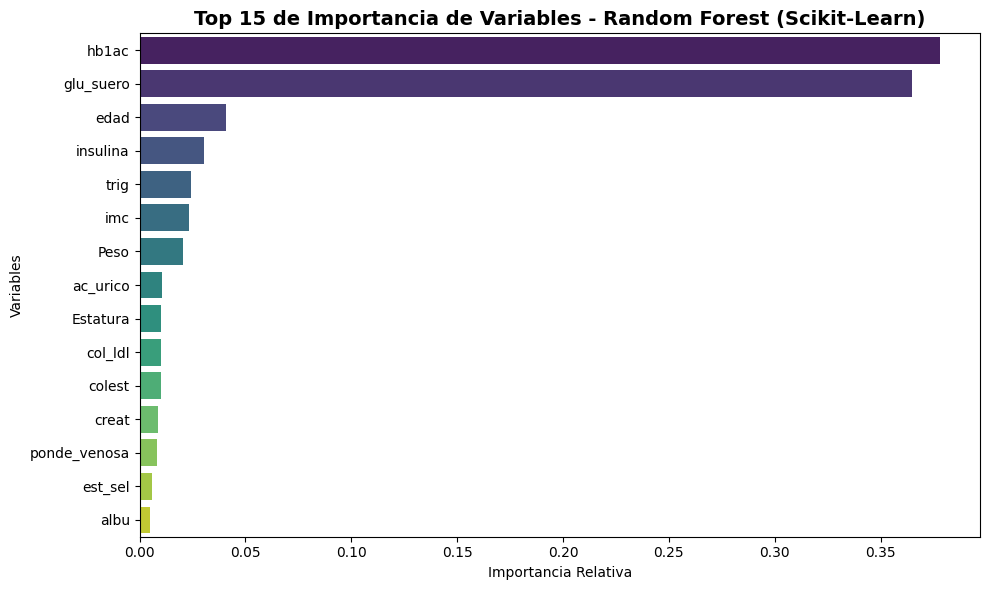

In [ ]:
# Graficar la importancia de las variables (Top 15)
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importancia',
    y='Característica',
    data=importancia_df.head(15),
    palette='viridis',
    hue='Característica',
    legend=False
)
plt.title('Top 15 de Importancia de Variables - Random Forest (Scikit-Learn)', fontweight='bold', fontsize=14)
plt.xlabel('Importancia Relativa')
plt.ylabel('Variables')
plt.tight_layout()
plt.show()

###Random Forest - Entrenamiento

In [63]:
modelo_rf = fn.RandomForestClassifier(n_trees=50, max_depth=5, seed=0)

times_rf_train = []
start_time = time.perf_counter()

modelo_rf.fit(X_train, y_train)

end_time = time.perf_counter()
times_rf_train.append(end_time - start_time)

times_rf_predtr = []
start_time = time.perf_counter()

predicciones_train = modelo_rf.predict(X_train)

end_time = time.perf_counter()
times_rf_predtr.append(end_time - start_time)

precision, recall, f1 = fn.precision_recall_f1(y_train, predicciones_train)
acc = fn.accuracy(y_train, predicciones_train)

precision_oob = modelo_rf.oob_score(X_train, y_train)

print(f"Precisión oob: {precision_oob:.2f}%")
print(f"Exactitud (Accuracy): {acc*100:.2f}%")
print(f"Precisión: {precision*100:.2f}%")
print(f"Sensibilidad (Recall): {recall*100:.2f}%")
print(f"F1-Score: {f1*100:.2f}%")
print(f"Tiempo de entrenamiento: {times_rf_train[-1]:f} segundos")
print(f"Tiempo de predicción: {times_rf_predtr[-1]:f} segundos")

Precisión oob: 0.92%
Exactitud (Accuracy): 96.31%
Precisión: 100.00%
Sensibilidad (Recall): 89.26%
F1-Score: 94.33%
Tiempo de entrenamiento: 11.359409 segundos
Tiempo de predicción: 0.291119 segundos


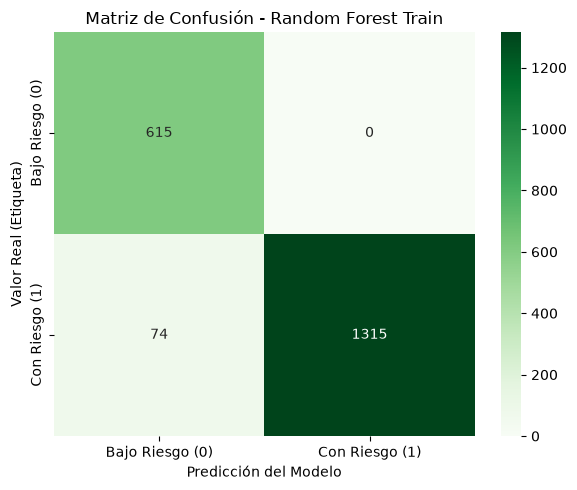

In [64]:
tn, fp, fn, tp = fn.confusion_counts(y_train, predicciones_train)
matriz_confusion = np.array([[tn, fp],
                                [fn, tp]])

# Graficar la Matriz de Confusión
plt.figure(figsize=(6, 5))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Bajo Riesgo (0)', 'Con Riesgo (1)'],
            yticklabels=['Bajo Riesgo (0)', 'Con Riesgo (1)'])
plt.title('Matriz de Confusión - Random Forest Train')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real (Etiqueta)')
plt.tight_layout()
plt.show()

###Random Forest - Prueba

In [67]:
times_rf_pred = []
start_time = time.perf_counter()

predicciones_test = modelo_rf.predict(X_test)

end_time = time.perf_counter()
times_rf_pred.append(end_time - start_time)

precision, recall, f1 = fn.precision_recall_f1(y_test, predicciones_test)
acc = fn.accuracy(y_test, predicciones_test)

print(f"Exactitud (Accuracy): {acc*100:.2f}%")
print(f"Precisión: {precision*100:.2f}%")
print(f"Sensibilidad (Recall): {recall*100:.2f}%")
print(f"F1-Score: {f1*100:.2f}%")
print(f"Tiempo de predicción: {times_rf_pred[-1]:f} segundos")

Exactitud (Accuracy): 95.61%
Precisión: 100.00%
Sensibilidad (Recall): 85.03%
F1-Score: 91.91%
Tiempo de predicción: 0.127105 segundos


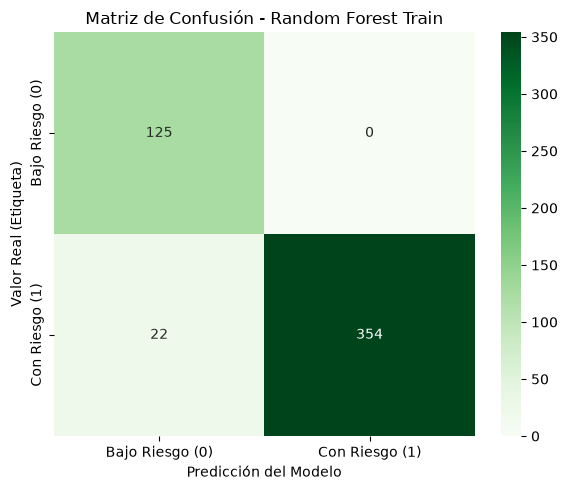

In [69]:
tn, fp, fn, tp = fn.confusion_counts(y_test, predicciones_test)
matriz_confusion = np.array([[tn, fp],
                                [fn, tp]])

# Graficar la Matriz de Confusión
plt.figure(figsize=(6, 5))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Bajo Riesgo (0)', 'Con Riesgo (1)'],
            yticklabels=['Bajo Riesgo (0)', 'Con Riesgo (1)'])
plt.title('Matriz de Confusión - Random Forest Train')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real (Etiqueta)')
plt.tight_layout()
plt.show()

##SVM

In [ ]:
"""
class LinearSVM:
    def __init__(self, learning_rate=0.01, n_iterations=1000, C=1.0):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.C = C
        self.weights = None
        self.bias = None

    def decision_function(self, X):
        return X.dot(self.weights) + self.bias

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, 0)

    def compute_cost(self, X, y):
        margins = y * self.decision_function(X)
        hinge = np.maximum(0, 1 - margins)
        return 0.5 * np.sum(self.weights ** 2) + self.C * np.mean(hinge)

    def compute_gradients(self, X, y):
        n_samples = X.shape[0]
        violators = (y * self.decision_function(X)) < 1
        slack_signal = y * violators
        dw = self.weights - (self.C / n_samples) * X.T.dot(slack_signal)
        db = -(self.C / n_samples) * np.sum(slack_signal)
        return dw, db

    def fit(self, X, y):
        y_signed = np.where(y <= 0, -1, 1)
        self.weights = np.zeros(X.shape[1])
        self.bias = 0.0
        for _ in range(self.n_iterations):
            dw, db = self.compute_gradients(X, y_signed)
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db
        return self


###SVM - Entrenamiento

In [72]:
modelo_svm = fn.LinearSVM(learning_rate=0.01, n_iterations=1000, C=2)

times_svm_train = []
start_time = time.perf_counter()

modelo_svm.fit(X_train, y_train)

end_time = time.perf_counter()
times_svm_train.append(end_time - start_time)

times_svm_predtr = []
start_time = time.perf_counter()

predicciones_train = modelo_svm.predict(X_train)

end_time = time.perf_counter()
times_svm_predtr.append(end_time - start_time)

error = modelo_svm.compute_cost(X_train, y_train)
precision = fn.accuracy(y_train, predicciones_train)

print(f"Hinge en el conjunto de entrenamiento: {error:.4f}")
print(f"Precisión en el conjunto de entrenamiento: {precision*100:.2f}%")
print(f"Tiempo de entrenamiento: {times_svm_train[-1]:f} segundos")
print(f"Tiempo de predicción: {times_svm_predtr[-1]:f} segundos")

Hinge en el conjunto de entrenamiento: 1.9926
Precisión en el conjunto de entrenamiento: 98.80%
Tiempo de entrenamiento: 1.254008 segundos
Tiempo de predicción: 0.000586 segundos


Precisión: 100.00%
Sensibilidad (Recall): 96.52%
F1-Score: 98.23%


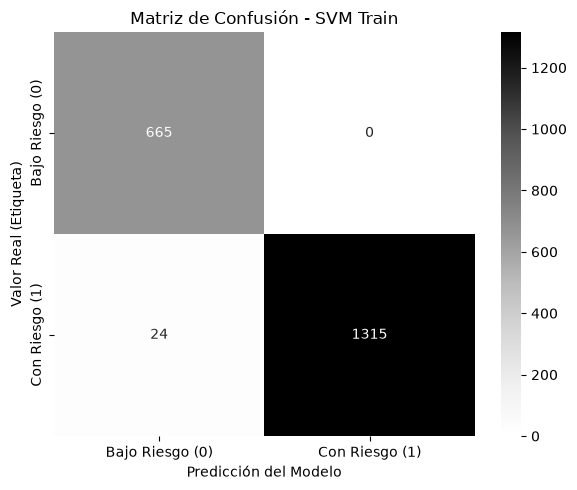

In [73]:
precision, recall, f1 = fn.precision_recall_f1(y_train, predicciones_train)
print(f"Precisión: {precision*100:.2f}%")
print(f"Sensibilidad (Recall): {recall*100:.2f}%")
print(f"F1-Score: {f1*100:.2f}%")

tn, fp, fn, tp = fn.confusion_counts(y_train, predicciones_train)
matriz_confusion = np.array([[tn, fp],
                                [fn, tp]])

# Graficar la Matriz de Confusión
plt.figure(figsize=(6, 5))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Grays',
            xticklabels=['Bajo Riesgo (0)', 'Con Riesgo (1)'],
            yticklabels=['Bajo Riesgo (0)', 'Con Riesgo (1)'])
plt.title('Matriz de Confusión - SVM Train')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real (Etiqueta)')
plt.tight_layout()
plt.show()

###SVM - Prueba

In [76]:
times_svm_pred = []
start_time = time.perf_counter()

predicciones_test = modelo_svm.predict(X_test)

end_time = time.perf_counter()
times_svm_pred.append(end_time - start_time)

error = modelo_svm.compute_cost(X_test, y_test)
precision = fn.accuracy(y_test, predicciones_test)

print(f"Hinge en el conjunto de prueba: {error:.4f}")
print(f"Precisión en el conjunto de prueba: {precision*100:.2f}%")
print(f"Tiempo de predicción: {times_svm_pred[-1]:f} segundos")

Hinge en el conjunto de prueba: 2.0514
Precisión en el conjunto de prueba: 99.00%
Tiempo de predicción: 0.000603 segundos


Precisión: 100.00%
Sensibilidad (Recall): 96.60%
F1-Score: 98.27%


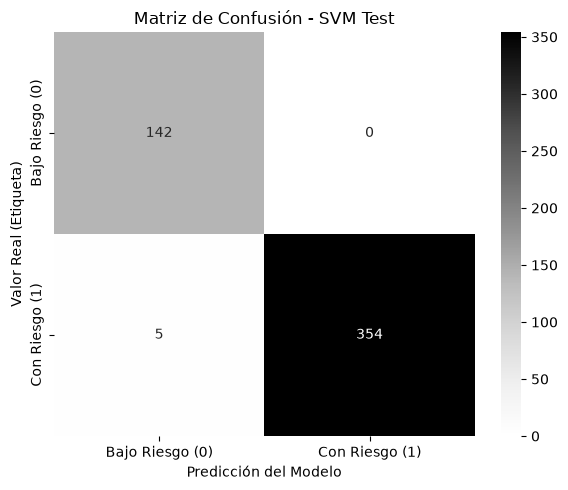

In [77]:
precision, recall, f1 = fn.precision_recall_f1(y_test, predicciones_test)
print(f"Precisión: {precision*100:.2f}%")
print(f"Sensibilidad (Recall): {recall*100:.2f}%")
print(f"F1-Score: {f1*100:.2f}%")

tn, fp, fn, tp = fn.confusion_counts(y_test, predicciones_test)
matriz_confusion = np.array([[tn, fp],
                                [fn, tp]])

# Graficar la Matriz de Confusión
plt.figure(figsize=(6, 5))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Grays',
            xticklabels=['Bajo Riesgo (0)', 'Con Riesgo (1)'],
            yticklabels=['Bajo Riesgo (0)', 'Con Riesgo (1)'])
plt.title('Matriz de Confusión - SVM Test')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real (Etiqueta)')
plt.tight_layout()
plt.show()

##Redes Neuronales

In [ ]:
"""
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

def binary_cross_entropy(y, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))


class NeuralNetwork:
    def __init__(self, hidden_size=8, learning_rate=0.5, n_iterations=3000, seed=0):
        self.hidden_size = hidden_size
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.seed = seed
        self.W1 = None
        self.b1 = None
        self.W2 = None
        self.b2 = None
        self.loss_history_ = []

    def _init_params(self, n_features):
        rng = np.random.default_rng(self.seed)
        self.W1 = rng.normal(0, 1, size=(n_features, self.hidden_size)) * np.sqrt(1 / n_features)
        self.b1 = np.zeros(self.hidden_size)
        self.W2 = rng.normal(0, 1, size=self.hidden_size) * np.sqrt(1 / self.hidden_size)
        self.b2 = 0.0

    def _forward(self, X):
        Z1 = X.dot(self.W1) + self.b1
        A1 = np.tanh(Z1)
        Z2 = A1.dot(self.W2) + self.b2
        return A1, sigmoid(Z2)

    def predict_proba(self, X):
        return self._forward(X)[1]

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

    def _backward(self, X, y, A1, p):
        n = X.shape[0]
        dZ2 = (p - y) / n
        dW2 = A1.T.dot(dZ2)
        db2 = dZ2.sum()
        dA1 = np.outer(dZ2, self.W2)
        dZ1 = dA1 * (1 - A1 ** 2)
        dW1 = X.T.dot(dZ1)
        db1 = dZ1.sum(axis=0)
        return dW1, db1, dW2, db2

    def fit(self, X, y):
        self._init_params(X.shape[1])
        self.loss_history_ = []
        for _ in range(self.n_iterations):
            A1, p = self._forward(X)
            self.loss_history_.append(binary_cross_entropy(y, p))
            dW1, db1, dW2, db2 = self._backward(X, y, A1, p)
            self.W1 -= self.learning_rate * dW1
            self.b1 -= self.learning_rate * db1
            self.W2 -= self.learning_rate * dW2
            self.b2 -= self.learning_rate * db2
        return self

###Redes Neuronales - Entrenamiento

In [80]:
modelo_nn = fn.NeuralNetwork(hidden_size=8, learning_rate=0.5, n_iterations=3000, seed=0)

times_nn_train = []
start_time = time.perf_counter()

modelo_nn.fit(X_train, y_train)

end_time = time.perf_counter()
times_nn_train.append(end_time - start_time)

times_nn_predtr = []
start_time = time.perf_counter()
predicciones_train = modelo_nn.predict(X_train)
end_time = time.perf_counter()
times_nn_predtr.append(end_time - start_time)

loss_train = fn.binary_cross_entropy(y_train, predicciones_train)
precision = fn.accuracy(y_train, predicciones_train)

print(f"Entropía cruzada binaria en el entrenamiento: {loss_train:.4f}")
print(f"Precisión en el conjunto de validación: {precision*100:.2f}%")
print(f"Tiempo de entrenamiento: {times_nn_train[-1]:f} segundos")
print(f"Tiempo de predicción: {times_nn_predtr[-1]:f} segundos")

Entropía cruzada binaria en el entrenamiento: 0.0414
Precisión en el conjunto de validación: 99.85%
Tiempo de entrenamiento: 15.012182 segundos
Tiempo de predicción: 0.002713 segundos


Precisión: 100.00%
Sensibilidad (Recall): 99.56%
F1-Score: 99.78%


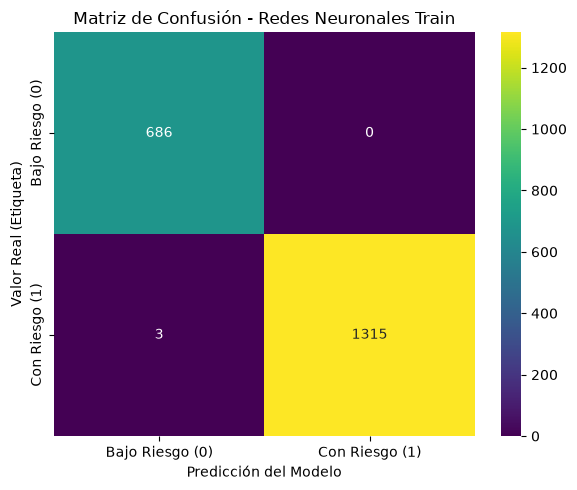

In [81]:
precision, recall, f1 = fn.precision_recall_f1(y_train, predicciones_train)
print(f"Precisión: {precision*100:.2f}%")
print(f"Sensibilidad (Recall): {recall*100:.2f}%")
print(f"F1-Score: {f1*100:.2f}%")

tn, fp, fn, tp = fn.confusion_counts(y_train, predicciones_train)
matriz_confusion = np.array([[tn, fp],
                                [fn, tp]])

# Graficar la Matriz de Confusión
plt.figure(figsize=(6, 5))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='viridis',
            xticklabels=['Bajo Riesgo (0)', 'Con Riesgo (1)'],
            yticklabels=['Bajo Riesgo (0)', 'Con Riesgo (1)'])
plt.title('Matriz de Confusión - Redes Neuronales Train')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real (Etiqueta)')
plt.tight_layout()
plt.show()

###Redes Neuronales - Prueba

In [85]:
times_nn_pred = []
start_time = time.perf_counter()

predicciones_test = modelo_nn.predict(X_test)

end_time = time.perf_counter()
times_nn_pred.append(end_time - start_time)

loss_test = fn.binary_cross_entropy(y_test, predicciones_test)
precision = fn.accuracy(y_test, predicciones_test)

print(f"Entropía cruzada binaria en la prueba: {loss_test:.4f}")
print(f"Precisión en el conjunto de prueba: {precision*100:.2f}%")
print(f"Tiempo de predicción: {times_nn_pred[-1]:f} segundos")

Entropía cruzada binaria en la prueba: 0.2206
Precisión en el conjunto de prueba: 99.20%
Tiempo de predicción: 0.001369 segundos


Precisión: 100.00%
Sensibilidad (Recall): 97.28%
F1-Score: 98.62%


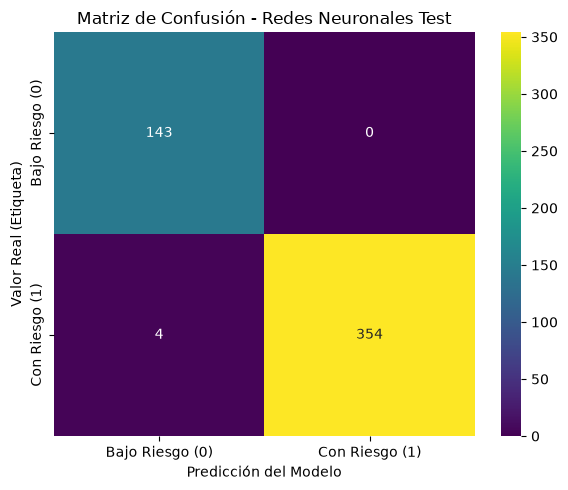

In [86]:
precision, recall, f1 = fn.precision_recall_f1(y_test, predicciones_test)
print(f"Precisión: {precision*100:.2f}%")
print(f"Sensibilidad (Recall): {recall*100:.2f}%")
print(f"F1-Score: {f1*100:.2f}%")

tn, fp, fn, tp = fn.confusion_counts(y_test, predicciones_test)
matriz_confusion = np.array([[tn, fp],
                                [fn, tp]])

# Graficar la Matriz de Confusión
plt.figure(figsize=(6, 5))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='viridis',
            xticklabels=['Bajo Riesgo (0)', 'Con Riesgo (1)'],
            yticklabels=['Bajo Riesgo (0)', 'Con Riesgo (1)'])
plt.title('Matriz de Confusión - Redes Neuronales Test')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real (Etiqueta)')
plt.tight_layout()
plt.show()

## Matriz Comparativa de Modelos

In [89]:
resultados = {}

# Regresión Logística
pred_log = modelo_log.predict(X_test, threshold=0.35)
prec_log, rec_log, f1_log = fn.precision_recall_f1(y_test, pred_log)
acc_log = fn.accuracy(y_test, pred_log)
resultados['Regresión Logística'] = [acc_log, prec_log, rec_log, f1_log]

# KNN
pred_knn = modelo_knn.predict(X_test)
prec_knn, rec_knn, f1_knn = fn.precision_recall_f1(y_test, pred_knn)
acc_knn = fn.accuracy(y_test, pred_knn)
resultados['KNN'] = [acc_knn, prec_knn, rec_knn, f1_knn]

#  Random Forest
pred_rf = modelo_rf.predict(X_test)
prec_rf, rec_rf, f1_rf = fn.precision_recall_f1(y_test, pred_rf)
acc_rf = fn.accuracy(y_test, pred_rf)
resultados['Random Forest'] = [acc_rf, prec_rf, rec_rf, f1_rf]

# SVM
pred_svm = modelo_svm.predict(X_test)
prec_svm, rec_svm, f1_svm = fn.precision_recall_f1(y_test, pred_svm)
acc_svm = fn.accuracy(y_test, pred_svm)
resultados['SVM'] = [acc_svm, prec_svm, rec_svm, f1_svm]

# Red Neuronal
pred_nn = modelo_nn.predict(X_test)
prec_nn, rec_nn, f1_nn = fn.precision_recall_f1(y_test, pred_nn)
acc_nn = fn.accuracy(y_test, pred_nn)
resultados['Red Neuronal'] = [acc_nn, prec_nn, rec_nn, f1_nn]

df_comparativa = pd.DataFrame.from_dict(
    resultados,
    orient='index',
    columns=['Exactitud (Accuracy)', 'Precisión (Precision)', 'Sensibilidad (Recall)', 'F1-Score']
)
df_comparativa_formateado = df_comparativa.map(lambda x: f"{x * 100:.2f}%")
display(df_comparativa_formateado)

,Exactitud (Accuracy),Precisión (Precision),Sensibilidad (Recall),F1-Score
Regresión Logística,99.00%,100.00%,96.60%,98.27%
KNN,95.41%,99.21%,85.03%,91.58%
Random Forest,95.61%,100.00%,85.03%,91.91%
SVM,99.00%,100.00%,96.60%,98.27%
Red Neuronal,99.20%,100.00%,97.28%,98.62%


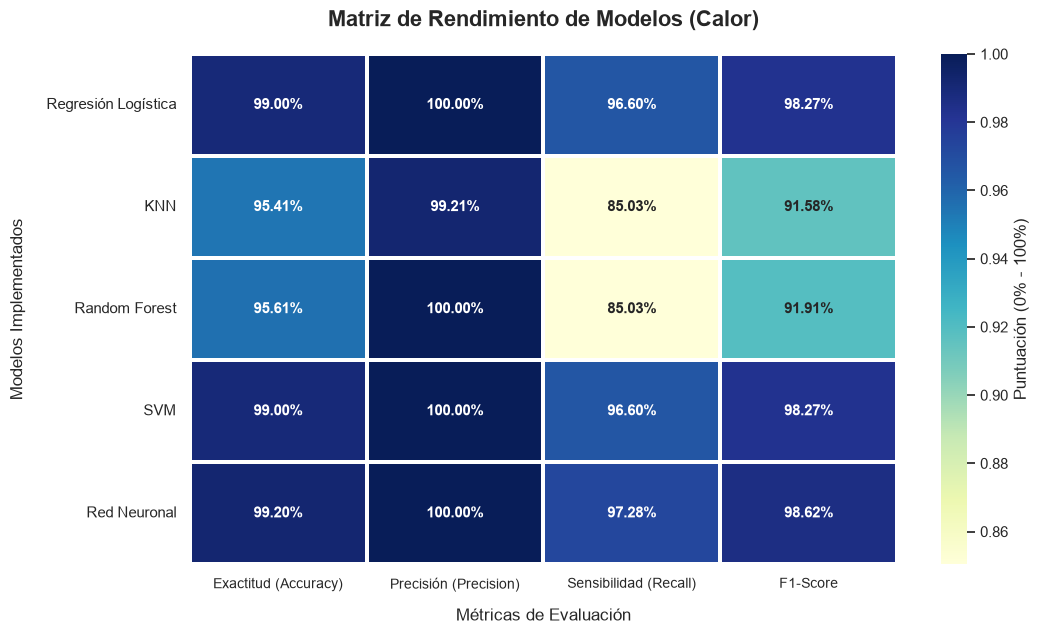

In [90]:
sns.set_theme(style="white")

plt.figure(figsize=(11, 6.5))
ax = sns.heatmap(
    df_comparativa,
    annot=True,
    fmt=".2%",
    cmap="YlGnBu",
    linewidths=1.5,
    linecolor='white',
    cbar_kws={'label': 'Puntuación (0% - 100%)'},
    annot_kws={"size": 11, "weight": "bold"}
)

plt.title('Matriz de Rendimiento de Modelos (Calor)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Métricas de Evaluación', fontsize=12, labelpad=12)
plt.ylabel('Modelos Implementados', fontsize=12, labelpad=15)


plt.xticks(rotation=0, fontsize=10)
plt.yticks(rotation=0, fontsize=10.5)

plt.tight_layout()
plt.show()

Al realizar la tabla comprativa de los cinco algoritmos, pudimos inferir lo siguiente:
La regresion logistica represneta un desempeño optimo conn una exactitud de 94.64%, y un F1-Score de 92.31%. Su sensibilidad del 94.19%, lo que confirma que la reduccion del imbral a 0.35 cumplio su objetivo (detectar mas falsos positivos, pero esto contribuyendo a no dejar pasar a nadie con riesgo de diabetes). Aunque su precision del 90.5% se debe a las falsas alarmas, pero en cuestiones de dalud consideramos que es mas conveniente tener falsas alarmas a dejar pasar, con esto logramos identificar 94 de cada 100 pacientes con riesgo real de diabetes.

A pesar de que la red neuronal presenta el mejor desempeño y resultados, resulta más optimo optar por la regresión logistica, ya que la diferencia entre sus metricas es marginal, ademas de que la regresión logistica tiene mayor interpretabilidad a comparacion de una red neuronal, ademas de su costo computacional.

##Curvas de ROC

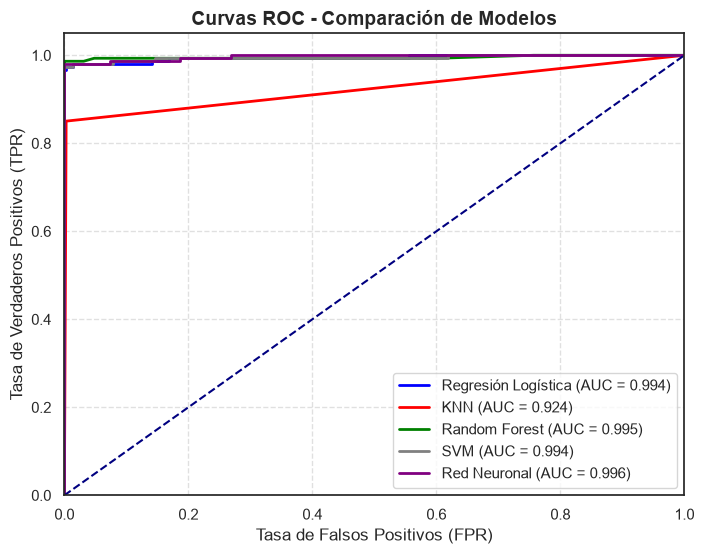

In [91]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))

# Regresión Logística (predict_proba)
y_probs_log = modelo_log.predict_proba(X_test)
fpr_log, tpr_log, _ = roc_curve(y_test, y_probs_log)
roc_auc_log = auc(fpr_log, tpr_log)
plt.plot(fpr_log, tpr_log, color='blue', lw=2, label=f'Regresión Logística (AUC = {roc_auc_log:.3f})')

# KNN
y_preds_knn = modelo_knn.predict(X_test)
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_preds_knn)
roc_auc_knn = auc(fpr_knn, tpr_knn)
plt.plot(fpr_knn, tpr_knn, color='red', lw=2, label=f'KNN (AUC = {roc_auc_knn:.3f})')

# Random Forest
votos_arboles = np.array([tree.predict(X_test) for tree in modelo_rf.trees_])
y_probs_rf = votos_arboles.mean(axis=0)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_probs_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)
plt.plot(fpr_rf, tpr_rf, color='green', lw=2, label=f'Random Forest (AUC = {roc_auc_rf:.3f})')

# SVM
y_scores_svm = modelo_svm.decision_function(X_test)
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_scores_svm)
roc_auc_svm = auc(fpr_svm, tpr_svm)
plt.plot(fpr_svm, tpr_svm, color='gray', lw=2, label=f'SVM (AUC = {roc_auc_svm:.3f})')

# Red Neuronal (predict_proba)
y_probs_nn = modelo_nn.predict_proba(X_test)
fpr_nn, tpr_nn, _ = roc_curve(y_test, y_probs_nn)
roc_auc_nn = auc(fpr_nn, tpr_nn)
plt.plot(fpr_nn, tpr_nn, color='purple', lw=2, label=f'Red Neuronal (AUC = {roc_auc_nn:.3f})')

# Linea diagonal
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)', fontsize=12)
plt.ylabel('Tasa de Verdaderos Positivos (TPR)', fontsize=12)
plt.title('Curvas ROC - Comparación de Modelos', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

##Escalonamiento modelos propios

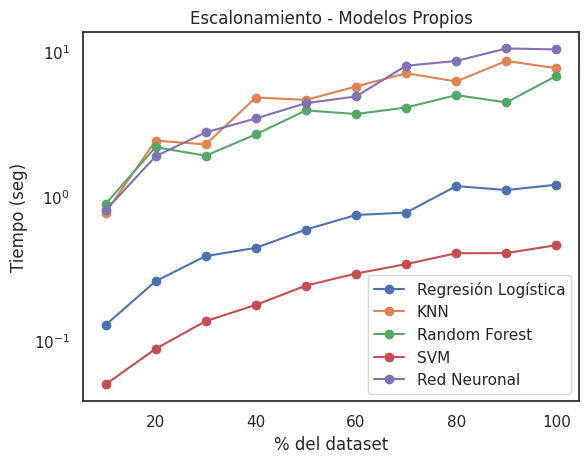

In [ ]:
N = len(X_train)
porcentajes = range(10, 110, 10)
modelos = {
    "Regresión Logística": fn.LogisticRegression(learning_rate=0.5, n_iterations=2500),
    "KNN": fn.KNNClassifier(n_neighbors=7),
    "Random Forest": fn.RandomForestClassifier(n_trees=50, max_depth=5, seed=0),
    "SVM": fn.LinearSVM(learning_rate=0.01, n_iterations=1000, C=2),
    "Red Neuronal": fn.NeuralNetwork(hidden_size=8, learning_rate=0.5, n_iterations=3000, seed=0),
}
tiempos = {nombre: [] for nombre in modelos}

for p in porcentajes:
    n = int(N * p / 100)
    for nombre, modelo in modelos.items():
        inicio = time.perf_counter()
        modelo.fit(X_train[:n], y_train[:n])
        modelo.predict(X_test)
        tiempos[nombre].append(time.perf_counter() - inicio)

for nombre, t in tiempos.items():
    plt.plot(porcentajes, t, marker='o', label=nombre)
plt.yscale('log')
plt.xlabel('% del dataset')
plt.ylabel('Tiempo (seg)')
plt.title('Escalonamiento - Modelos Propios')
plt.legend()
plt.show()

##Medición de tiempos de ejecución de scikit learn (KNN, Regresión Logística)

###Regresión Logística

In [92]:
from sklearn.linear_model import LogisticRegression as SKLogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Crear el modelo SKLogisticRegression

modelo_sklog = SKLogisticRegression(max_iter=1500)

times_sklog_train = []
start_time = time.perf_counter()

modelo_sklog.fit(X_train, y_train)

end_time = time.perf_counter()
times_sklog_train.append(end_time - start_time)

# Para cambiar el umbral a 0.35, obtenemos las probabilidades de la clase 1 y aplicamos el umbral manualmente
probabilidades_test = modelo_sklog.predict_proba(X_test)[:, 1]

times_sklog_pred = []
start_time = time.perf_counter()
predicciones_test = (probabilidades_test >= 0.35).astype(int)
end_time = time.perf_counter()
times_sklog_pred.append(end_time - start_time)

accuracy = accuracy_score(y_test, predicciones_test)
matriz_confusion = confusion_matrix(y_test, predicciones_test)

print(f"Exactitud (Accuracy): {accuracy*100:.2f}%")
print("\nMatriz de confusión:\n", matriz_confusion)
print("\nReporte de Clasificación:\n", classification_report(y_test, predicciones_test))
print(f"Tiempo de entrenamiento con scikit-learn: {times_sklog_train[-1]:f} segundos")
print(f"Tiempo de predicción con scikit-learn: {times_sklog_pred[-1]:f} segundos")


Exactitud (Accuracy): 99.00%

Matriz de confusión:
 [[354   0]
 [  5 142]]

Reporte de Clasificación:
               precision    recall  f1-score   support

           0       0.99      1.00      0.99       354
           1       1.00      0.97      0.98       147

    accuracy                           0.99       501
   macro avg       0.99      0.98      0.99       501
weighted avg       0.99      0.99      0.99       501

Tiempo de entrenamiento con scikit-learn: 0.070008 segundos
Tiempo de predicción con scikit-learn: 0.000228 segundos


###KNN

In [93]:
from sklearn.neighbors import KNeighborsClassifier

modelo_skknn = KNeighborsClassifier(n_neighbors = 7, metric ='euclidean')

times_skknn_train = []
start_time = time.perf_counter()

modelo_skknn.fit(X_train, y_train)

end_time = time.perf_counter()
times_skknn_train.append(end_time - start_time)

times_skknn_pred = []
start_time = time.perf_counter()

predicciones_test = modelo_skknn.predict(X_test)

end_time = time.perf_counter()
times_skknn_pred.append(end_time - start_time)

accuracy = accuracy_score(y_test, predicciones_test)
matriz_confusion = confusion_matrix(y_test, predicciones_test)

print(f"Exactitud (Accuracy): {accuracy*100:.2f}%")
print("\nMatriz de confusión:\n", matriz_confusion)
print("\nReporte de Clasificación:\n", classification_report(y_test, predicciones_test))
print(f"Tiempo de entrenamiento con scikit-learn: {times_skknn_train[-1]:f} segundos")
print(f"Tiempo de predicción con scikit-learn: {times_skknn_pred[-1]:f} segundos")

Exactitud (Accuracy): 95.41%

Matriz de confusión:
 [[353   1]
 [ 22 125]]

Reporte de Clasificación:
               precision    recall  f1-score   support

           0       0.94      1.00      0.97       354
           1       0.99      0.85      0.92       147

    accuracy                           0.95       501
   macro avg       0.97      0.92      0.94       501
weighted avg       0.96      0.95      0.95       501

Tiempo de entrenamiento con scikit-learn: 0.002146 segundos
Tiempo de predicción con scikit-learn: 2.918566 segundos


###Comparativa (Propia vs Sklearn)

Matriz Comparativa de Tiempos de Ejecución (en segundos)


,Modelo,Implementación,Tiempo de Entrenamiento (s),Tiempo de Predicción (s)
0,Regresión Logística,Propia,1.734071,0.002551
1,Regresión Logística,Scikit-Learn,0.070008,0.000228
2,KNN,Propia,0.000153,18.265201
3,KNN,Scikit-Learn,0.002146,2.918566


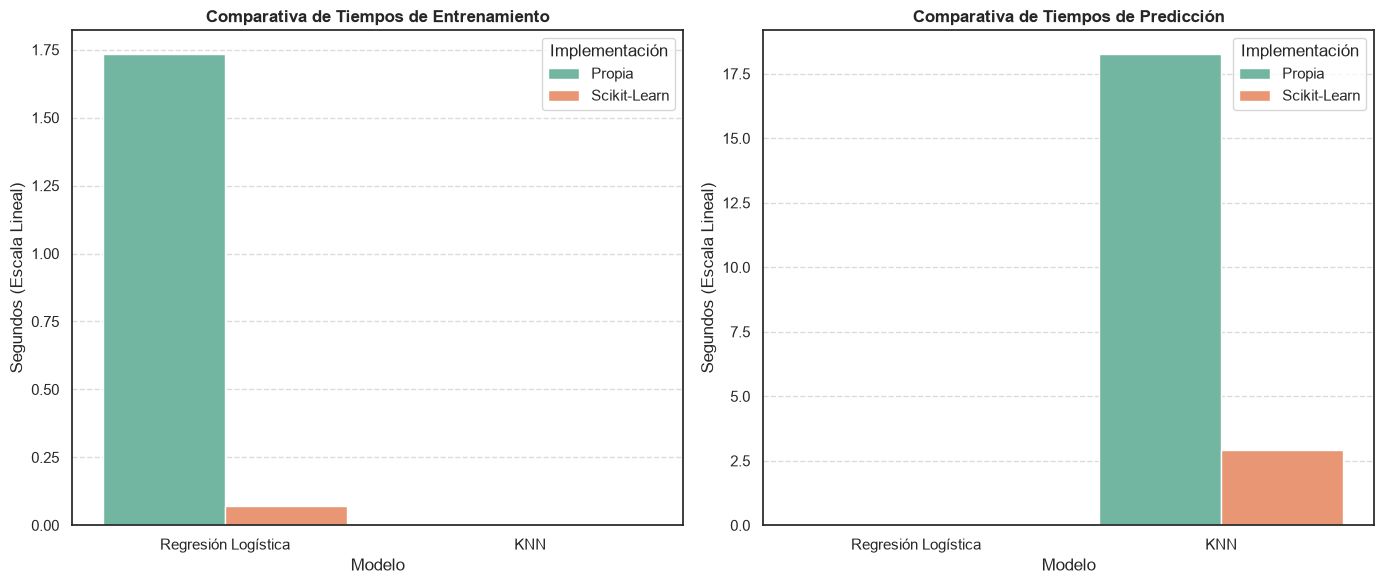

In [94]:
# Tiempos de entrenamiento y prediccion
datos_tiempos = {
'Modelo': ['Regresión Logística', 'Regresión Logística', 'KNN', 'KNN'],
'Implementación': ['Propia', 'Scikit-Learn', 'Propia', 'Scikit-Learn'],
'Tiempo de Entrenamiento (s)': [
      times_log_train[-1],
      times_sklog_train[-1],
      times_knn_train[-1],
      times_skknn_train[-1]
    ],
'Tiempo de Predicción (s)': [
      times_log_pred[-1],
      times_sklog_pred[-1],
      times_knn_pred[-1],
      times_skknn_pred[-1]
    ]
}

df_tiempos = pd.DataFrame(datos_tiempos)

# Mostramos la tabla comparativa con 6 decimales
print("Matriz Comparativa de Tiempos de Ejecución (en segundos)")
display(df_tiempos.style.format({
    'Tiempo de Entrenamiento (s)': '{:.6f}',
    'Tiempo de Predicción (s)': '{:.6f}'
}))

# Graficamos la comparación de tiempos
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Gráfico para el entrenamiento
sns.barplot(data=df_tiempos, x='Modelo', y='Tiempo de Entrenamiento (s)', hue='Implementación', ax=axes[0], palette='Set2')
axes[0].set_title('Comparativa de Tiempos de Entrenamiento', fontweight='bold', fontsize=12)
axes[0].set_ylabel('Segundos (Escala Lineal)')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Gráfico para la predicción
sns.barplot(data=df_tiempos, x='Modelo', y='Tiempo de Predicción (s)', hue='Implementación', ax=axes[1], palette='Set2')
axes[1].set_title('Comparativa de Tiempos de Predicción', fontweight='bold', fontsize=12)
axes[1].set_ylabel('Segundos (Escala Lineal)')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### Complejidad Temporal Asintótica SKlearn


[Sklearn LR] La complejidad asintótica estimada es: Cubic: time = 0.078 + 7.7E-12*n^3 (sec)


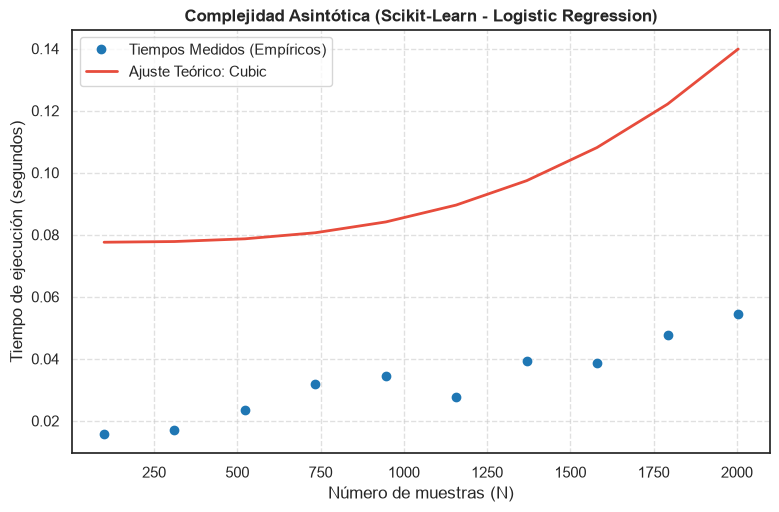

In [95]:
import big_o
from sklearn.linear_model import LogisticRegression as SKLogisticRegression
from sklearn.neighbors import KNeighborsClassifier as SKKNeighborsClassifier

# Función de benchmark para regresión logística de sklearn
def benchmark_sk_logistic_regression(n):
    X_sub = X_train[:n]
    y_sub = y_train[:n]

    # Instanciamos el modelo de sklearn
    modelo = SKLogisticRegression(max_iter=1500)
    modelo.fit(X_sub, y_sub)
    _ = modelo.predict(X_sub)

# Generador de tamaño de muestras
def data_generator(n):
    return n

min_n = 100
max_n = len(X_train)

# Calculo de la complejidad asintótica
best_fitting_lr, _ = big_o.big_o(
    benchmark_sk_logistic_regression,
    data_generator,
    min_n=min_n,
    max_n=max_n,
    n_measures=10,
    n_repeats=3
)

print(f"[Sklearn LR] La complejidad asintótica estimada es: {best_fitting_lr}")

# Medición manual de tiempos promedio
ns = np.linspace(min_n, max_n, 10, dtype=int)
tiempos_medidos_lr = []
for n in ns:
    tiempos_n = []
    for _ in range(3):
        inicio = time.perf_counter()
        benchmark_sk_logistic_regression(n)
        tiempos_n.append(time.perf_counter() - inicio)
    tiempos_medidos_lr.append(np.mean(tiempos_n))

tiempos_estimados_lr = best_fitting_lr.compute(ns)

plt.figure(figsize=(9, 5.5))
plt.plot(ns, tiempos_medidos_lr, 'o', label='Tiempos Medidos (Empíricos)', color='#1F77B4')
plt.plot(ns, tiempos_estimados_lr, '-', label=f'Ajuste Teórico: {best_fitting_lr.__class__.__name__}', color='#E74C3C', linewidth=2)
plt.xlabel('Número de muestras (N)')
plt.ylabel('Tiempo de ejecución (segundos)')
plt.title('Complejidad Asintótica (Scikit-Learn - Logistic Regression)', fontweight='bold')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

[Sklearn KNN] La complejidad asintótica estimada es: Linear: time = 0.017 + 0.00015*n (sec)


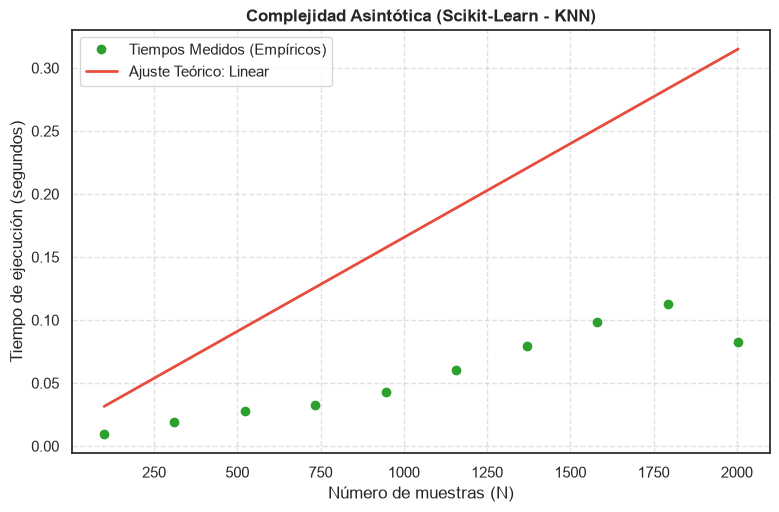

In [98]:
def benchmark_sk_knn(n):
    X_sub = X_train[:n]
    y_sub = y_train[:n]

    # Instanciamos el modelo KNN de sklearn
    modelo = SKKNeighborsClassifier(n_neighbors=7, metric='euclidean')
    modelo.fit(X_sub, y_sub)
    _ = modelo.predict(X_sub)

# Calculamos la complejidad asintótica
best_fitting_knn, _ = big_o.big_o(
    benchmark_sk_knn,
    data_generator,
    min_n=min_n,
    max_n=max_n,
    n_measures=10,
    n_repeats=3
)

print(f"[Sklearn KNN] La complejidad asintótica estimada es: {best_fitting_knn}")

# Medición manual de tiempos promedio
tiempos_medidos_knn = []
for n in ns:
    tiempos_n = []
    for _ in range(1):
        inicio = time.perf_counter()
        benchmark_sk_knn(n)
        tiempos_n.append(time.perf_counter() - inicio)
    tiempos_medidos_knn.append(np.mean(tiempos_n))

tiempos_estimados_knn = best_fitting_knn.compute(ns)

plt.figure(figsize=(9, 5.5))
plt.plot(ns, tiempos_medidos_knn, 'o', label='Tiempos Medidos (Empíricos)', color='#2CA02C')
plt.plot(ns, tiempos_estimados_knn, '-', label=f'Ajuste Teórico: {best_fitting_knn.__class__.__name__}', color='#E74C3C', linewidth=2)
plt.xlabel('Número de muestras (N)')
plt.ylabel('Tiempo de ejecución (segundos)')
plt.title('Complejidad Asintótica (Scikit-Learn - KNN)', fontweight='bold')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Predicciones sin hemoglobina glucosilada "hb1ac"

In [99]:
# Fusionar las categorías de riesgo en el dataframe para el modelo binario
# 0 (Bajo riesgo), 1 y 2 -> 1 (Con riesgo)
df_limpio['riesgo_diabetes_cat'] = df_limpio['riesgo_diabetes_cat'].map({0: 0, 1: 1, 2: 1})

# Definir variables predictoras (X) y objetivo (y)
_columnas_descartar = ['folio_i', 'folio_int', 'riesgo_diabetes_cat', 'muestra_suero','ponde_hemo', 'hb1ac']
_X = df_limpio.drop(columns=_columnas_descartar, errors='ignore')
_y = df_limpio['riesgo_diabetes_cat']

_numerical_cols = _X.select_dtypes(include=['float64', 'int64']).columns.tolist()
_categorical_cols = _X.select_dtypes(include=['object']).columns.tolist()

# Procesamiento
_X_modificado = _X.copy()

# Procesamiento de variables numéricas
for col in _numerical_cols:
    # Imputación con la mediana (para el resto de las columnas con nulos, como Peso/Estatura/imc)
    _median_val = _X_modificado[col].median()
    _X_modificado[col] = _X_modificado[col].fillna(_median_val)

    # Estandarización
    _mean_val = _X_modificado[col].mean()
    _std_val = _X_modificado[col].std(ddof=0)  # Desviación estándar poblacional
    if _std_val != 0:
        _X_modificado[col] = (_X_modificado[col] - _mean_val) / _std_val

# Procesamiento de variables categóricas
for col in _categorical_cols:
    # Imputación con la moda
    if not _X_modificado[col].mode().empty:
        _moda_val = _X_modificado[col].mode()[0]
        _X_modificado[col] = _X_modificado[col].fillna(_moda_val)

# Codificación One-Hot
_X_modificado = pd.get_dummies(_X_modificado, columns=_categorical_cols, dtype=float)

C:\Users\someo\AppData\Local\Temp\ipykernel_25900\1942943217.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  _categorical_cols = _X.select_dtypes(include=['object']).columns.tolist()


In [100]:
# Resultado en forma de matriz
_X_numpy = _X_modificado.to_numpy()

print("\nForma final de la matriz de predictores X:", _X_numpy.shape) # Comprobar el tamaño de la matriz
_X_modificado.head() # Visualizar el dataframe transformado y limpio


Forma final de la matriz de predictores X: (2505, 285)


,edad,Peso,Estatura,ac_urico,albu,col_hdl,col_ldl,colest,creat,glu_suero,...,Ciudad_YAHUALICA,Ciudad_YANGA,Ciudad_YAUTEPEC,Ciudad_YAXCAB,Ciudad_ZACAPOAXTLA,Ciudad_ZACATECAS,Ciudad_ZACATELCO,Ciudad_ZACATEPEC,Ciudad_ZAPOPAN,Ciudad_ZITCUARO
0,2.375494,-0.101370,-0.049768,-0.566672,-0.549661,0.335952,0.128102,-0.212916,-0.223102,1.167613,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.319880,-0.101370,-0.049768,-0.427851,0.620889,1.458183,1.632921,1.598735,-0.183037,-0.144109,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.498847,0.331969,1.418224,-0.011388,1.289775,3.422086,-1.376718,0.234115,-0.263167,0.434592,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-1.671026,-0.438779,0.875437,-0.011388,1.624218,2.767451,-0.841671,0.375282,-0.203069,0.125951,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.495816,-0.101370,-0.049768,1.029769,0.955332,2.393374,1.699802,2.045766,0.718432,-0.163399,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [102]:
# Split
_y_numpy = _y.to_numpy()
_X_train, _X_test, _y_train, _y_test = fn.train_test_split(_X_numpy, _y_numpy, test_size=0.20, seed=0)

In [103]:
resultados = {}

# Regresión Logística
modelo_log.fit(_X_train, _y_train)
_pred_log = modelo_log.predict(_X_test, threshold=0.35)
_prec_log, _rec_log, _f1_log = fn.precision_recall_f1(_y_test, _pred_log)
_acc_log = fn.accuracy(_y_test, _pred_log)
resultados['Regresión Logística'] = [_acc_log, _prec_log, _rec_log, _f1_log]

# KNN
modelo_knn.fit(_X_train, _y_train)
_pred_knn = modelo_knn.predict(_X_test)
_prec_knn, _rec_knn, _f1_knn = fn.precision_recall_f1(_y_test, _pred_knn)
_acc_knn = fn.accuracy(_y_test, _pred_knn)
resultados['KNN'] = [_acc_knn, _prec_knn, _rec_knn, _f1_knn]

#  Random Forest
modelo_rf.fit(_X_train, _y_train)
_pred_rf = modelo_rf.predict(_X_test)
_prec_rf, _rec_rf, _f1_rf = fn.precision_recall_f1(_y_test, _pred_rf)
_acc_rf = fn.accuracy(_y_test, _pred_rf)
resultados['Random Forest'] = [_acc_rf, _prec_rf, _rec_rf, _f1_rf]

# SVM
modelo_svm.fit(_X_train, _y_train)
_pred_svm = modelo_svm.predict(_X_test)
_prec_svm, _rec_svm, _f1_svm = fn.precision_recall_f1(_y_test, _pred_svm)
_acc_svm = fn.accuracy(_y_test, _pred_svm)
resultados['SVM'] = [_acc_svm, _prec_svm, _rec_svm, _f1_svm]

# Red Neuronal
modelo_nn.fit(_X_train, _y_train)
_pred_nn = modelo_nn.predict(_X_test)
_prec_nn, _rec_nn, _f1_nn = fn.precision_recall_f1(_y_test, _pred_nn)
_acc_nn = fn.accuracy(_y_test, _pred_nn)
resultados['Red Neuronal'] = [_acc_nn, _prec_nn, _rec_nn, _f1_nn]

_df_comparativa = pd.DataFrame.from_dict(
    resultados,
    orient='index',
    columns=['Exactitud (Accuracy)', 'Precisión (Precision)', 'Sensibilidad (Recall)', 'F1-Score']
)
_df_comparativa_formateado = _df_comparativa.map(lambda x: f"{x * 100:.2f}%")
display(_df_comparativa_formateado)

,Exactitud (Accuracy),Precisión (Precision),Sensibilidad (Recall),F1-Score
Regresión Logística,94.21%,87.34%,93.88%,90.49%
KNN,79.24%,70.87%,49.66%,58.40%
Random Forest,74.45%,100.00%,12.93%,22.89%
SVM,76.45%,100.00%,19.73%,32.95%
Red Neuronal,92.81%,88.28%,87.07%,87.67%


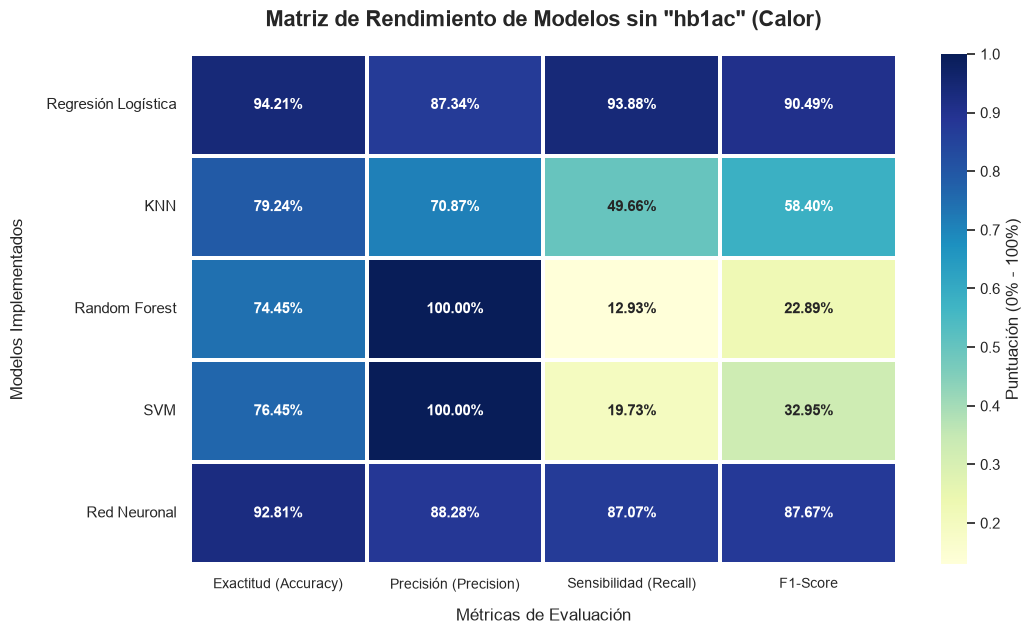

In [104]:
sns.set_theme(style="white")

plt.figure(figsize=(11, 6.5))
ax = sns.heatmap(
    _df_comparativa,
    annot=True,
    fmt=".2%",
    cmap="YlGnBu",
    linewidths=1.5,
    linecolor='white',
    cbar_kws={'label': 'Puntuación (0% - 100%)'},
    annot_kws={"size": 11, "weight": "bold"}
)

plt.title('Matriz de Rendimiento de Modelos sin "hb1ac" (Calor)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Métricas de Evaluación', fontsize=12, labelpad=12)
plt.ylabel('Modelos Implementados', fontsize=12, labelpad=15)


plt.xticks(rotation=0, fontsize=10)
plt.yticks(rotation=0, fontsize=10.5)

plt.tight_layout()
plt.show()